# Out-of-sample quarterly EPS forecasting — Shanghai & Shenzhen A-shares, FY2005–FY2021Q1

This notebook compares four expectation models for quarterly earnings per share (EPS) in a genuine
rolling-window, out-of-sample design. The forecasts are meant as inputs to alternative unexpected-earnings
measures, $UE^{(m)}_{i,q} = EPS_{i,q} - \widehat{EPS}^{(m)}_{i,q}$, for later PEAD research.
The goal here is forecast accuracy only, so no asset-pricing tests are run.

| # | Model | Forecast of $EPS_{i,q}$ | Estimation |
|---|---|---|---|
| M1 | Seasonal random walk (SRW, benchmark) | $EPS_{i,q-4}$ | none |
| M2 | SRW with drift | $EPS_{i,q-4} + \hat\mu_i$ | firm-specific mean of YoY changes in the window |
| M3 | Foster (1977) seasonal AR(1) | $EPS_{i,q-4} + \hat\alpha_i + \hat\phi_i\,\Delta_4 EPS_{i,q-1}$ | firm-specific OLS in the window |
| M4 | XGBoost | $EPS_{i,q-4} + \widehat{\Delta_4 EPS}_{i,q}$ | pooled across firms in the window |

**Common design for all models**
* **Target:** every firm–fiscal-quarter announced in FY2005Q1–FY2021Q1 (FY2021 contains Q1 only).
* **Forecast origin / information cutoff:** the day before the target's own announcement date $A_{i,q}$.
  Forecast inputs may only use EPS announced strictly before $A_{i,q}$.
* **Parameter estimation:** may only use EPS announced strictly before the first day of the announcement
  month, $M_{i,q} \le A_{i,q}$. This lets the pooled XGBoost be re-estimated monthly while giving every
  model the same estimation information.
* **Rolling window:** 12 fiscal quarters ($q-12,\dots,q-1$) of training *targets*. Lags needed to build
  those training observations can come from earlier quarters, which are also historical.
* **Horizon:** "next announcement". Because Chinese annual (Q4) and Q1 reports are often released on the
  same day, $EPS_{q-1}$ is sometimes not yet public. `h_avail` records how many quarters back the newest
  available EPS lies, and models that use $EPS_{q-1}$ handle the gap explicitly.

**Reproducibility.** The `eps-forecast` conda environment is defined in `environment.yml` (conda-forge:
Python 3.12, numpy, pandas, statsmodels, xgboost, matplotlib, pyarrow). Execute with
`conda activate eps-forecast && jupyter nbconvert --to notebook --execute --inplace notebooks/eps_forecasting.ipynb`.
All randomness (XGBoost row/column subsampling, test sampling) uses seed 42.
Runtime is reported at the end of the notebook. Most of it is XGBoost tuning and refitting, plus the
end-to-end look-ahead test, which re-runs the whole pipeline on perturbed future data.

## 1. Setup

In [1]:
import time
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import scipy.stats as st
import statsmodels
import statsmodels.api as sm
import xgboost as xgb
import matplotlib as mpl
import matplotlib.pyplot as plt

try:
    display
except NameError:  # running as a plain script
    display = print

T_START = time.time()
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'clean'
OUT = ROOT / 'output'
FC_DIR, TAB_DIR, FIG_DIR = OUT / 'forecasts', OUT / 'tables', OUT / 'figures'
REPORT_DIR = ROOT / 'report'
for d in (FC_DIR, TAB_DIR, FIG_DIR, REPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
RNG = np.random.default_rng(SEED)

# ---- design parameters (common to all models) ----
FIRST_FY, LAST_FY = 2005, 2021    # target fiscal years; FY2021 has Q1 only (panel ends May 2021)
WINDOW = 12                       # rolling window: training targets in fiscal quarters q-12..q-1
MIN_DS_DRIFT = 4                  # M2: minimum number of YoY changes to estimate the drift
MIN_PAIRS_FOSTER = 8              # M3: minimum (dS_s, dS_{s-1}) pairs for the firm-specific OLS
MIN_PAIRS_POOLED = 4              # M3b (robustness): minimum pairs per firm for the pooled-phi variant
MAX_TARGET_LAG = 365              # targets announced > 1 year after quarter end are not evaluated
SCALE_FLOOR = 0.01                # CNY; floor for the historical EPS scale used by XGBoost
MIN_XGB_TRAIN = 1000              # minimum pooled training rows for an XGBoost fit
MIN_FIRM_OBS = 12                 # firm-level comparisons: >= 12 common-sample forecasts (3 years)
XGB_THREADS = 8
FIRST_INFO_FY = 2001              # oldest fiscal year used to build XGBoost training rows

MODELS = ['rw', 'rwd', 'foster', 'xgb']
ALT = ['rwd', 'foster', 'xgb']
LABEL = {'rw': 'SRW', 'rwd': 'SRW + drift', 'foster': 'Foster', 'xgb': 'XGBoost',
         'foster_pooled': 'Foster, pooled $\\phi$'}
LABEL_TXT = {**LABEL, 'foster_pooled': 'Foster, pooled phi'}

# ---- figure style: neutral benchmark + first three validated categorical slots ----
COL = {'rw': '#52514e', 'rwd': '#2a78d6', 'foster': '#eb6834', 'xgb': '#1baf7a', 'foster_pooled': '#6250d6'}
MARK = {'rw': 'o', 'rwd': 's', 'foster': '^', 'xgb': 'D', 'foster_pooled': 'v'}
INK, INK2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'font.size': 9,
    'font.family': 'sans-serif', 'axes.titlesize': 10, 'axes.labelsize': 9,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': GRID, 'grid.linewidth': 0.6, 'legend.frameon': False, 'legend.fontsize': 8,
    'lines.linewidth': 1.8, 'lines.markersize': 5, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
})


def savefig(fig, name):
    fig.savefig(FIG_DIR / f'{name}.pdf')
    fig.savefig(FIG_DIR / f'{name}.png', dpi=200)


for m in (np, pd, scipy, statsmodels, xgb, mpl):
    print(f'{m.__name__:12s} {m.__version__}')
print('python      ', platform.python_version(), '|', platform.platform())
print('project root', ROOT)

numpy        1.26.4
pandas       2.2.3
scipy        1.17.1
statsmodels  0.14.6
xgboost      3.4.2
matplotlib   3.9.4
python       3.12.15 | macOS-15.3.1-arm64-arm-64bit
project root /Users/csillagb/Documents/personal/earnings_forecast


## 2. Raw data: structure of the monthly panel

The input is `shanghai_shenzhen_monthly.dta`. Only identifiers, the quarterly EPS fields and their
publication dates are read. Analyst fields (`eps_12fwd`, `eps_12high`, …) are deliberately ignored.

In [2]:
RAW_COLS = (['permno', 'date', 'exchange'] + [f'eps_q{k}' for k in range(1, 5)]
            + [f'date_q{k}' for k in range(1, 5)] + [f'basiceps_q{k}' for k in range(1, 5)])
raw = pd.read_stata(DATA / 'shanghai_shenzhen_monthly.dta', columns=RAW_COLS, convert_categoricals=False)

assert not raw.duplicated(['permno', 'date']).any(), 'duplicate firm-months'
assert (raw.groupby('permno').exchange.nunique() == 1).all(), 'firm listed on two exchanges'
assert (raw.date.dt.day == 1).all()
print(f'{len(raw):,} firm-months, {raw.permno.nunique():,} firms, {raw.date.min():%Y-%m} to {raw.date.max():%Y-%m}')
display(raw.groupby('exchange').permno.nunique().rename('firms').to_frame())

515,915 firm-months, 3,594 firms, 1991-02 to 2021-05


,firms
exchange,
shanghai,1607
shenzhen,1987


**How the panel stores quarterly EPS.** Each calendar year's monthly rows carry that fiscal year's four
quarterly EPS values (`basiceps_q1..q4` is constant within firm × calendar year). `eps_qk` and `date_qk`
are filled only in the three rows of calendar quarter $k$. So **a monthly row can hold EPS that is not yet
public**: in the example below, the January–March 2008 rows already show Q1-2008 EPS, which was published
on 18 April 2008. Any analysis that uses `eps_q*` by row date leaks future information. The data are
therefore rebuilt at the firm–fiscal-quarter level, and *availability* is defined only by the publication
date `date_qk`.

In [3]:
ex = raw[raw.permno.str.startswith('KWEICHOW MOUTAI') & raw.date.between('2008-01-01', '2009-01-01')]
display(ex[['date', 'basiceps_q1', 'basiceps_q4', 'eps_q1', 'eps_q2', 'eps_q3', 'eps_q4',
            'date_q1', 'date_q2', 'date_q3', 'date_q4']].iloc[::2])

,date,basiceps_q1,basiceps_q4,eps_q1,eps_q2,eps_q3,eps_q4,date_q1,date_q2,date_q3,date_q4
76,2008-01-01,0.699,0.526,0.699,NaN,NaN,NaN,2008-04-18,NaT,NaT,NaT
78,2008-03-01,0.699,0.526,0.699,NaN,NaN,NaN,2008-04-18,NaT,NaT,NaT
80,2008-05-01,0.699,0.526,NaN,1.082,NaN,NaN,NaT,2008-08-26,NaT,NaT
82,2008-07-01,0.699,0.526,NaN,NaN,0.721,NaN,NaT,NaT,2008-10-23,NaT
84,2008-09-01,0.699,0.526,NaN,NaN,0.721,NaN,NaT,NaT,2008-10-23,NaT
86,2008-11-01,0.699,0.526,NaN,NaN,NaN,0.526,NaT,NaT,NaT,2009-03-23
88,2009-01-01,0.962,0.421,0.962,NaN,NaN,NaN,2009-04-17,NaT,NaT,NaT


## 3. Firm–fiscal-quarter table

Construction rules:
1. Stack `(eps_qk, date_qk)` from the calendar-quarter-$k$ rows; fiscal year = calendar year of the row.
   A handful of values sit in rows of the wrong calendar quarter ("misplaced"). These are dropped after
   checking they also appear in the correct rows.
2. Collapse the three monthly copies to one record per firm × fiscal year × quarter, and assert they agree.
3. *Stale repeats*: an identical (EPS, date) pair recorded for the same quarter in two different fiscal
   years is a vendor carry-forward (FY2000–2002). All copies are dropped.
4. Dates: reporting lag = date − fiscal quarter end. Dates before quarter end are invalid. Dates far beyond
   the statutory deadline (Q1/Q3: 30/31 days, H1: 2 months, annual: 4 months) are flagged as *late*;
   for FY2000–2003 these are mostly vendor backfill dates (Nov 2003 – Jan 2004).
5. **Usable as information** = EPS present, valid date, not a stale repeat. EPS without a valid date is
   never used: its availability is unknown. Late/backfilled dates are later than the true release, so
   using them is conservative and cannot leak.
6. **Evaluation target** = usable, FY2005–FY2021, lag ≤ 365 days.

In [4]:
raw['row_year'] = raw.date.dt.year
raw['cal_q'] = raw.date.dt.quarter
parts = []
for k in range(1, 5):
    sel = raw[f'eps_q{k}'].notna() | raw[f'date_q{k}'].notna()
    p = raw.loc[sel, ['permno', 'exchange', 'date', 'row_year', 'cal_q', f'eps_q{k}', f'date_q{k}']]
    parts.append(p.rename(columns={f'eps_q{k}': 'eps', f'date_q{k}': 'ann_date'}).assign(fq=k))
long = pd.concat(parts, ignore_index=True)
long['misplaced'] = long.cal_q != long.fq

key = ['permno', 'fq', 'eps', 'ann_date']
mis = long[long.misplaced].drop_duplicates(key)
found = mis.merge(long.loc[~long.misplaced, key].drop_duplicates(), how='left', on=key, indicator=True)
print(f'misplaced monthly rows: {long.misplaced.sum()} ({mis.permno.nunique()} firms); '
      f'{(found._merge == "both").mean():.0%} of their values also appear in the correct rows')

fqt = (long[~long.misplaced]
       .groupby(['permno', 'row_year', 'fq'])
       .agg(exchange=('exchange', 'first'), eps=('eps', 'first'), ann_date=('ann_date', 'first'),
            n_eps=('eps', 'nunique'), n_date=('ann_date', 'nunique'), n_rows=('date', 'size'))
       .reset_index().rename(columns={'row_year': 'fy'}))
assert (fqt.n_eps <= 1).all() and (fqt.n_date <= 1).all(), 'EPS/date not constant within a calendar quarter'
assert not fqt.duplicated(['permno', 'fy', 'fq']).any()

both = fqt.eps.notna() & fqt.ann_date.notna()
rep = fqt[both].duplicated(['permno', 'fq', 'eps', 'ann_date'], keep=False)
fqt['stale_repeat'] = False
fqt.loc[rep[rep].index, 'stale_repeat'] = True

fqt['t'] = fqt.fy * 4 + fqt.fq - 1                     # running fiscal-quarter index
fqt['fperiod'] = fqt.fy.astype(str) + 'Q' + fqt.fq.astype(str)
fqt['fq_end'] = pd.to_datetime(dict(year=fqt.fy, month=3 * fqt.fq, day=1)) + pd.offsets.MonthEnd(0)
fqt['deadline'] = pd.to_datetime(dict(year=fqt.fy + (fqt.fq == 4), month=fqt.fq.map({1: 4, 2: 8, 3: 10, 4: 4}),
                                      day=fqt.fq.map({1: 30, 2: 31, 3: 31, 4: 30})))
fqt['lag_days'] = (fqt.ann_date - fqt.fq_end).dt.days
fqt['date_flag'] = np.select(
    [fqt.ann_date.isna(), fqt.lag_days < 0, fqt.ann_date > fqt.deadline + pd.Timedelta(days=30)],
    ['missing', 'before_qend', 'late'], 'ok')
fqt['usable'] = fqt.eps.notna() & fqt.ann_date.notna() & (fqt.lag_days >= 0) & ~fqt.stale_repeat
fqt['is_target'] = (fqt.usable & fqt.fy.between(FIRST_FY, LAST_FY) & (fqt.lag_days <= MAX_TARGET_LAG))
assert not fqt.duplicated(['permno', 't']).any()
assert (fqt.t % 4 + 1 == fqt.fq).all()

dq = (fqt[fqt.eps.notna()].assign(
        missing_date=lambda x: x.date_flag.eq('missing'), invalid_date=lambda x: x.date_flag.eq('before_qend'),
        late_date=lambda x: x.date_flag.eq('late'))
      .groupby('fy').agg(eps_records=('eps', 'size'), missing_date=('missing_date', 'sum'),
                         invalid_date=('invalid_date', 'sum'), late_date=('late_date', 'sum'),
                         stale_repeat=('stale_repeat', 'sum'), usable=('usable', 'sum'),
                         targets=('is_target', 'sum')))
dq = dq.loc[1999:]
dq.to_csv(TAB_DIR / 'data_quality_by_fy.csv')
print(f'firm-quarters with EPS: {fqt.eps.notna().sum():,}; usable as information: {fqt.usable.sum():,}; '
      f'evaluation targets: {fqt.is_target.sum():,}')
display(dq)

misplaced monthly rows: 138 (6 firms); 100% of their values also appear in the correct rows


firm-quarters with EPS: 143,900; usable as information: 141,900; evaluation targets: 127,454


,eps_records,missing_date,invalid_date,late_date,stale_repeat,usable,targets
fy,,,,,,,
1999,203,170,0,0,0,33,0
2000,1565,522,0,999,57,986,0
2001,2247,285,1,1702,121,1840,0
2002,3804,265,3,2955,85,3451,0
2003,3985,202,1,808,0,3782,0
2004,4198,18,0,78,2,4178,0
2005,4372,1,0,90,3,4368,4336
2006,4413,2,0,84,4,4407,4331
2007,4920,0,0,9,2,4918,4917


### 3.1 Are the EPS figures standalone quarterly values?
Chinese interim reports present year-to-date figures. If `eps_q2..q4` were cumulative, $EPS_{Q2}/EPS_{Q1}$
would be ≈ 2, $EPS_{Q4}/EPS_{Q1}$ ≈ 4, and almost all profitable firm-years would rise monotonically
through the year. The ratios below (firm-years with four positive quarters) show standalone quarterly EPS.

In [5]:
wide = fqt[fqt.usable].pivot_table(index=['permno', 'fy'], columns='fq', values='eps')
wide.columns = [f'q{c}' for c in wide.columns]
pos = wide.dropna()
pos = pos[(pos > 0).all(axis=1)]
standalone = pos.groupby(level='fy').apply(lambda x: pd.Series({
    'firm_years': len(x), 'median_q2_q1': (x.q2 / x.q1).median(), 'median_q3_q1': (x.q3 / x.q1).median(),
    'median_q4_q1': (x.q4 / x.q1).median(),
    'share_monotone': ((x.q1 < x.q2) & (x.q2 < x.q3) & (x.q3 < x.q4)).mean()})).loc[2002:]
display(standalone.round(2))
assert standalone.median_q4_q1.median() < 2 and standalone.share_monotone.max() < 0.3, 'looks cumulative'
standalone.to_csv(TAB_DIR / 'standalone_check.csv')

,firm_years,median_q2_q1,median_q3_q1,median_q4_q1,share_monotone
fy,,,,,
2002,376.0,1.33,1.07,1.32,0.04
2003,444.0,1.27,1.10,1.40,0.06
2004,505.0,1.17,1.11,1.20,0.06
2005,547.0,1.21,1.05,1.22,0.06
2006,602.0,1.28,1.16,1.41,0.08
2007,742.0,1.42,1.28,1.61,0.08
2008,586.0,1.34,1.10,1.15,0.07
2009,758.0,1.44,1.42,1.72,0.14
2010,981.0,1.29,1.18,1.50,0.11


EPS levels also appear to be **retroactively adjusted for later capital changes** (bonus shares). For example,
Kweichow Moutai's FY2008–2010 quarterly sums equal its reported annual EPS divided by $1.1^3$, matching its
three later 10-for-1 bonus issues. Adjustment keeps year-over-year changes on a common share basis, which is
what all four models need. The levels are not the as-reported numbers, though, and `price` is unadjusted,
so price-scaled errors would be distorted. Evaluation therefore uses CNY per (adjusted) share, plus a
scale-free variant that divides by each firm's own historical EPS scale.

### 3.2 Information order vs. fiscal order
The fiscal order of quarters is not the order in which information arrives. The critical case is the
annual report (Q4 of year $Y-1$) versus the Q1 report of year $Y$, which share an April 30 deadline.

In [6]:
q1 = fqt[(fqt.fq == 1) & fqt.is_target][['permno', 'fy', 'ann_date']]
q4 = fqt[(fqt.fq == 4) & fqt.usable][['permno', 'fy', 'ann_date']].assign(fy=lambda x: x.fy + 1)
q14 = q1.merge(q4, on=['permno', 'fy'], suffixes=('_q1', '_q4'))
q14['order'] = np.sign((q14.ann_date_q4 - q14.ann_date_q1).dt.days).map(
    {-1: 'Q4 before Q1', 0: 'same day', 1: 'Q4 after Q1'})
order_q14 = pd.crosstab(q14.fy, q14.order, normalize='index')[['Q4 before Q1', 'same day', 'Q4 after Q1']]
order_q14['n'] = q14.groupby('fy').size()
display(order_q14.round(3))
order_q14.to_csv(TAB_DIR / 'q4_q1_release_order.csv')

seq = fqt[fqt.usable & (fqt.fy >= 2004)].sort_values(['permno', 't'])
seq = seq.assign(prev_t=seq.groupby('permno').t.shift(), prev_date=seq.groupby('permno').ann_date.shift())
seq = seq[seq.prev_t == seq.t - 1]
seq['prev_vs_current'] = np.sign((seq.prev_date - seq.ann_date).dt.days).map(
    {-1: 'q-1 earlier', 0: 'same day', 1: 'q-1 later'})
display(pd.crosstab(seq.fq, seq.prev_vs_current, margins=True))

lag_stats = (fqt[fqt.usable & (fqt.fy >= 2004)].groupby('fq').lag_days
             .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(0))
display(lag_stats)

order,Q4 before Q1,same day,Q4 after Q1,n
fy,,,,
2005,0.922,0.029,0.049,1026
2006,0.912,0.041,0.047,1053
2007,0.892,0.037,0.071,1092
2008,0.960,0.035,0.005,1240
2009,0.956,0.040,0.004,1314
2010,0.964,0.034,0.002,1338
2011,0.965,0.032,0.002,1647
2012,0.905,0.054,0.042,1864
2013,0.781,0.208,0.011,1993


prev_vs_current,q-1 earlier,q-1 later,same day,All
fq,,,,
1,24218,456,6263,30937
2,31508,6,11,31525
3,32031,15,12,32058
4,32283,6,0,32289
All,120040,483,6286,126809


,count,mean,std,min,1%,25%,50%,75%,99%,max
fq,,,,,,,,,,
1,32811.0,28.0,10.0,0.0,13.0,24.0,27.0,29.0,42.0,763.0
2,32689.0,51.0,14.0,1.0,21.0,46.0,54.0,58.0,65.0,672.0
3,32890.0,27.0,7.0,0.0,16.0,25.0,27.0,29.0,33.0,580.0
4,33359.0,98.0,30.0,10.0,32.0,84.0,101.0,114.0,129.0,1571.0


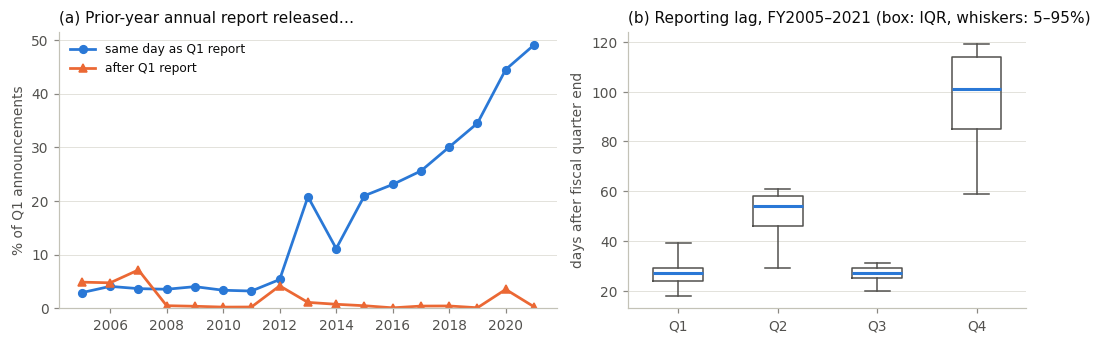

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2), gridspec_kw={'width_ratios': [1.25, 1]})
o = order_q14.loc[FIRST_FY:]
ax[0].plot(o.index, 100 * o['same day'], color=COL['rwd'], marker='o', label='same day as Q1 report')
ax[0].plot(o.index, 100 * o['Q4 after Q1'], color=COL['foster'], marker='^', label='after Q1 report')
ax[0].set_ylabel('% of Q1 announcements')
ax[0].set_title('(a) Prior-year annual report released…', loc='left')
ax[0].legend(loc='upper left')
ax[0].set_ylim(0, None)
lagd = fqt[fqt.usable & fqt.fy.between(FIRST_FY, LAST_FY) & (fqt.lag_days <= MAX_TARGET_LAG)]
ax[1].boxplot([lagd.loc[lagd.fq == k, 'lag_days'] for k in range(1, 5)], whis=(5, 95), showfliers=False,
              widths=0.5, medianprops=dict(color=COL['rwd'], linewidth=2), boxprops=dict(color=INK2),
              whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
ax[1].set_xticks(range(1, 5), ['Q1', 'Q2', 'Q3', 'Q4'])
ax[1].set_ylabel('days after fiscal quarter end')
ax[1].set_title('(b) Reporting lag, FY2005–2021 (box: IQR, whiskers: 5–95%)', loc='left')
fig.tight_layout()
savefig(fig, 'fig0_reporting_timing')
plt.show()

## 4. Information arrays
Usable EPS are stored in two dense matrices, firm × fiscal quarter. `E` holds EPS and `D` holds the
availability date in days since 1970; unusable cells get `NEVER`. Every forecast below reads the data
only through `gather()`, which masks any cell not announced strictly before the row's cutoff date.
That function is the single place where look-ahead is controlled.

In [8]:
NEVER = np.iinfo(np.int64).max // 2


def to_day(x):
    a = np.asarray(pd.to_datetime(pd.Series(x)).values, dtype='datetime64[D]')
    out = a.astype(np.int64)
    out[np.isnat(a)] = NEVER
    return out


def from_day(d):
    d = np.asarray(d, dtype=np.float64)
    ok = np.isfinite(d) & (d >= 0) & (d < NEVER)
    out = np.full(d.shape, np.datetime64('NaT'), dtype='datetime64[ns]')
    out[ok] = d[ok].astype(np.int64).astype('datetime64[D]')
    return out


def month_start(d):
    return np.asarray(d).astype('datetime64[D]').astype('datetime64[M]').astype('datetime64[D]').astype(np.int64)


firms = np.sort(fqt.permno.unique())
FIRM_IDX = pd.Series(np.arange(len(firms)), index=firms)
PAD = 20
T_BASE = int(fqt.t.min()) - PAD
N_T = int(fqt.t.max()) - T_BASE + 2

info = fqt[fqt.usable]
E = np.full((len(firms), N_T), np.nan)
D = np.full((len(firms), N_T), NEVER, dtype=np.int64)
i_fi = FIRM_IDX[info.permno].to_numpy()
i_ci = (info.t - T_BASE).to_numpy()
E[i_fi, i_ci] = info.eps.to_numpy()
D[i_fi, i_ci] = to_day(info.ann_date)
assert np.isfinite(E).sum() == len(info) and (D < NEVER).sum() == len(info)


def gather(E, D, fi, ci, offsets, cutoff):
    """EPS at fiscal quarters ci+offset for each row, kept only if announced strictly before `cutoff` (per row).
    Returns values (NaN if unavailable) and their announcement days (-1 if unavailable)."""
    cols = ci[:, None] + np.asarray(offsets)[None, :]
    v = E[fi[:, None], cols]
    d = D[fi[:, None], cols]
    ok = d < np.asarray(cutoff)[:, None]
    return np.where(ok, v, np.nan), np.where(ok, d, -1)


# targets and XGBoost training records
tgt = fqt[fqt.is_target].copy()
tgt['fi'] = FIRM_IDX[tgt.permno].to_numpy()
tgt['ci'] = (tgt.t - T_BASE).to_numpy()
tgt = tgt.sort_values(['ann_date', 'permno']).reset_index(drop=True)
rec = fqt[fqt.usable & (fqt.fy >= FIRST_INFO_FY)]
REC_FI = FIRM_IDX[rec.permno].to_numpy()
REC_CI = (rec.t - T_BASE).to_numpy()
print(f'{len(firms):,} firms x {N_T} quarters; {len(tgt):,} evaluation targets; '
      f'{len(rec):,} records for XGBoost training rows')

3,399 firms x 139 quarters; 127,454 evaluation targets; 140,822 records for XGBoost training rows


## 5. Forecasting models

**Notation.** $\Delta_4 EPS_{s} = EPS_{s} - EPS_{s-4}$ (year-over-year change). $A$ = target announcement
date; $M$ = first day of $A$'s month. The estimation window holds training targets $s \in \{q-12,\dots,q-1\}$.

* **M1 SRW:** $\widehat{EPS}_q = EPS_{q-4}$, requires $EPS_{q-4}$ announced before $A$.
* **M2 SRW + drift:** $\hat\mu$ = mean of the firm's $\Delta_4 EPS_s$ in the window, using EPS announced
  before $M$. Requires ≥ 4 changes.
* **M3 Foster:** firm-specific OLS $\Delta_4 EPS_s = \alpha + \phi\,\Delta_4 EPS_{s-1} + \varepsilon_s$ over
  window pairs announced before $M$. Requires ≥ 8 pairs and non-degenerate regressor variance. $\hat\phi$ is
  capped to $[-1, 1]$ (stationarity of the seasonal difference), and then
  $\hat\alpha = \overline{y - \hat\phi x}$. Forecast with $h=1$:
  $EPS_{q-4} + \hat\alpha + \hat\phi\,\Delta_4 EPS_{q-1}$. If $EPS_{q-1}$ is not yet public (Q4/Q1
  same-day releases), the model uses the two-step-ahead form
  $EPS_{q-4} + \hat\alpha(1+\hat\phi) + \hat\phi^2\,\Delta_4 EPS_{q-2}$.
* **M3b Foster, pooled $\phi$ (robustness only):** a single $\phi$ per window, from a within-firm (demeaned)
  pooled regression on firm-scaled, 1/99%-winsorized pairs of all firms. The firm-specific
  $\hat\alpha_i = \overline{y_i - \phi x_i}$ requires ≥ 4 pairs. This estimator carries the usual
  small-$T$ (Nickell) bias towards zero.
* **M4 XGBoost:** described in Section 6.

In [9]:
def firm_models(E, D, fi, ci, A, M, phi_pooled):
    """Vectorised M1, M2, M3, M3b for targets (fi, ci) with input cutoff A and estimation cutoff M."""
    lag, lagd = gather(E, D, fi, ci, -np.arange(1, 7), A)        # inputs: EPS_{q-1..q-6} known before A
    base = lag[:, 3]
    ds1, ds2 = lag[:, 0] - lag[:, 4], lag[:, 1] - lag[:, 5]
    w, wd = gather(E, D, fi, ci, -np.arange(1, 18), M)          # estimation: EPS_{q-1..q-17} known before M
    dS = w[:, :13] - w[:, 4:17]                                  # dS[:, j] = Delta4 EPS_{q-1-j}, j = 0..12
    y, x = dS[:, :12], dS[:, 1:13]                               # y: s = q-1..q-12 ; x: s-1
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        n_ds = np.isfinite(y).sum(1)
        mu = np.where(n_ds >= MIN_DS_DRIFT, np.nanmean(y, 1), np.nan)
        pair = np.isfinite(y) & np.isfinite(x)
        n_pairs = pair.sum(1)
        xm = np.where(pair, x, 0).sum(1) / n_pairs
        ym = np.where(pair, y, 0).sum(1) / n_pairs
        sxx = np.where(pair, (x - xm[:, None]) ** 2, 0).sum(1)
        sxy = np.where(pair, (x - xm[:, None]) * (y - ym[:, None]), 0).sum(1)
        phi_ols = np.where(sxx > 1e-10, sxy / sxx, np.nan)
        phi = np.clip(phi_ols, -1, 1)
        alpha = np.where(pair, y - phi[:, None] * x, 0).sum(1) / n_pairs
        alpha_p = np.where(pair, y - phi_pooled[:, None] * x, 0).sum(1) / n_pairs
    h1, h2 = np.isfinite(ds1), ~np.isfinite(ds1) & np.isfinite(ds2)

    def foster(a, p):
        f = np.where(h1, base + a + p * ds1, base + a * (1 + p) + p ** 2 * ds2)
        return np.where(h1 | h2, f, np.nan)

    ok3 = (n_pairs >= MIN_PAIRS_FOSTER) & np.isfinite(phi_ols)
    f_foster = np.where(ok3, foster(alpha, phi), np.nan)
    f_pool = np.where(n_pairs >= MIN_PAIRS_POOLED, foster(alpha_p, phi_pooled), np.nan)
    # dates of the inputs actually used (for the leakage assertions)
    in_d = np.where(np.isfinite(base), lagd[:, 3], -1)
    in_d = np.maximum(in_d, np.where(h1, np.maximum(lagd[:, 0], lagd[:, 4]), -1))
    in_d = np.maximum(in_d, np.where(h2, np.maximum(lagd[:, 1], lagd[:, 5]), -1))
    est_d = wd.max(1)
    return pd.DataFrame({
        'eps_lag4': base, 'f_rw': base, 'f_rwd': base + mu, 'f_foster': f_foster, 'f_foster_pooled': f_pool,
        'drift_mu': mu, 'n_ds_drift': n_ds, 'n_pairs_foster': n_pairs, 'foster_alpha': np.where(ok3, alpha, np.nan),
        'foster_phi': np.where(ok3, phi, np.nan), 'foster_phi_capped': ok3 & (np.abs(phi_ols) > 1),
        'foster_h': np.where(h1, 1, np.where(h2, 2, np.nan)), 'foster_pooled_phi': phi_pooled,
        'max_input_day_firm': in_d, 'max_est_day_firm': est_d})


def pooled_phi(E, D, ci, M):
    """Within-firm pooled phi across all firms for estimation window ending at quarter ci, cutoff M."""
    n = E.shape[0]
    w, _ = gather(E, D, np.arange(n), np.full(n, ci), -np.arange(1, 18), np.full(n, M))
    dS = w[:, :13] - w[:, 4:17]
    y, x = dS[:, :12], dS[:, 1:13]
    pair = np.isfinite(y) & np.isfinite(x)
    keep = pair.sum(1) >= MIN_PAIRS_POOLED
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        sc = np.maximum(np.nanmean(np.abs(w[:, :12]), 1), SCALE_FLOOR)[:, None]
    pair = pair & keep[:, None]
    xs, ys = x / sc, y / sc
    lo_x, hi_x = np.quantile(xs[pair], [0.01, 0.99])
    lo_y, hi_y = np.quantile(ys[pair], [0.01, 0.99])
    xs, ys = np.clip(xs, lo_x, hi_x), np.clip(ys, lo_y, hi_y)
    npair = np.maximum(pair.sum(1), 1)[:, None]
    xd = np.where(pair, xs - np.where(pair, xs, 0).sum(1)[:, None] / npair, 0)
    yd = np.where(pair, ys - np.where(pair, ys, 0).sum(1)[:, None] / npair, 0)
    return float(np.clip((xd * yd).sum() / (xd * xd).sum(), -1, 1))

## 6. XGBoost (M4)

**Target.** The scaled seasonal change $y_s = (EPS_s - EPS_{s-4})/\text{scale}_s$, where $\text{scale}_s$ is
the mean $|EPS|$ over the firm's last eight quarters known at the time (floored at 0.01 CNY). Scaling lets
one pooled model serve firms whose EPS differ by two orders of magnitude. The forecast is
$EPS_{q-4} + \hat y\cdot\text{scale}$, so M4 has exactly the same availability requirement as M1.

**Features.** Every feature is built *as of the row's own announcement date*: for training rows, that row's
date; for targets, $A$. Training rows therefore show the same information pattern as live forecasts,
including the missing $EPS_{q-1}$ for same-day Q4/Q1 releases. Unavailable lags stay `NaN`, which XGBoost
handles natively. Features: fiscal quarter; `h_avail`; scaled EPS lags 1–8 and 12; scaled YoY-change lags
1–4; mean, median and SD of the YoY changes in the 12-quarter window (drift and volatility); SD of EPS over
8 quarters; trailing-four-quarter growth; share of loss quarters; loss indicator at $q-4$; log scale;
number of available quarters.

**Training / tuning (no look-ahead).**
* Re-estimation batch = (target fiscal quarter $q$, announcement month). Training rows are all firms'
  records with fiscal quarter in $q-12..q-1$ announced before $M$. The training target is winsorized at the
  1st/99th percentiles *of that training set*.
* Hyperparameters are re-tuned once per calendar year $Y$ on information available on 1 January $Y$.
  The training rows of the 12-quarter window before the first fiscal quarter announced in $Y$ are split by
  *announcement date*. Rows announced during year $Y-1$ form the validation set; rows announced earlier form
  the fit set. Fit and validation targets therefore never overlap in time. Grid: depth {2, 3, 4} × min_child_weight {20, 100} × λ {1, 10};
  learning rate 0.05, subsample 0.8, colsample 0.8, early stopping (50 rounds, ≤ 1000 trees) on
  validation RMSE of the scaled target. The chosen tree count is reused when refitting.
* Re-estimations whose training set is identical to an earlier one reuse the fitted model.

In [10]:
FEATURES = (['fq', 'h_avail'] + [f'eps_l{k}' for k in (1, 2, 3, 4, 5, 6, 7, 8, 12)]
            + [f'ds_l{k}' for k in (1, 2, 3, 4)]
            + ['ds_mean12', 'ds_median12', 'ds_std12', 'n_ds12', 'eps_std8', 'ttm_growth', 'loss_share8',
               'loss_l4', 'log_scale', 'n_avail12'])


def build_features(E, D, fi, ci, A):
    lag, lagd = gather(E, D, fi, ci, -np.arange(1, 17), A)     # lag[:, k-1] = EPS_{q-k}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        n8 = np.isfinite(lag[:, :8]).sum(1)
        scale = np.where(n8 > 0, np.maximum(np.nanmean(np.abs(lag[:, :8]), 1), SCALE_FLOOR), np.nan)
        z = lag / scale[:, None]
        ds = z[:, :12] - z[:, 4:16]                              # ds[:, k-1] = Delta4 EPS_{q-k} / scale
        avail = np.isfinite(lag)
        f = {'fq': ((ci + T_BASE) % 4 + 1).astype(float),
             'h_avail': np.where(avail.any(1), avail.argmax(1) + 1, np.nan)}
        f.update({f'eps_l{k}': z[:, k - 1] for k in (1, 2, 3, 4, 5, 6, 7, 8, 12)})
        f.update({f'ds_l{k}': ds[:, k - 1] for k in (1, 2, 3, 4)})
        f.update({'ds_mean12': np.nanmean(ds, 1), 'ds_median12': np.nanmedian(ds, 1),
                  'ds_std12': np.nanstd(ds, 1, ddof=1), 'n_ds12': np.isfinite(ds).sum(1).astype(float),
                  'eps_std8': np.nanstd(z[:, :8], 1, ddof=1),
                  'ttm_growth': z[:, 0:4].sum(1) - z[:, 4:8].sum(1),
                  'loss_share8': np.where(n8 > 0, (lag[:, :8] < 0).sum(1) / np.maximum(n8, 1), np.nan),
                  'loss_l4': np.where(np.isfinite(lag[:, 3]), (lag[:, 3] < 0).astype(float), np.nan),
                  'log_scale': np.log(scale), 'n_avail12': avail[:, :12].sum(1).astype(float)})
    X = pd.DataFrame(f)[FEATURES].astype('float32')
    return X, lag[:, 3], scale, lagd.max(1)


def make_feature_table(E, D, fi, ci):
    A = D[fi, ci]
    X, base, scale, max_in = build_features(E, D, fi, ci, A)
    meta = pd.DataFrame({'fi': fi, 'ci': ci, 'A': A, 'base': base, 'scale': scale, 'max_input_day': max_in,
                         'y': (E[fi, ci] - base) / scale})
    return meta, X


XGB_FIXED = dict(objective='reg:squarederror', learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                 tree_method='hist', max_bin=256, n_jobs=XGB_THREADS, random_state=SEED)
GRID = [dict(max_depth=d, min_child_weight=m, reg_lambda=l) for d in (2, 3, 4) for m in (20, 100) for l in (1, 10)]


def tune_xgb(meta, X, year):
    C = to_day([f'{year}-01-01'])[0]
    t_ref = (year - 1) * 4 + 3 - T_BASE                      # Q4 of year-1: first fiscal quarter announced in `year`
    V = to_day([f'{year - 1}-01-01'])[0]
    win = (meta.ci >= t_ref - WINDOW) & (meta.ci <= t_ref - 1) & (meta.A < C) & meta.y.notna()
    val = win & (meta.A >= V)                                # targets announced during year-1
    fit = win & (meta.A < V)                                 # targets announced before year-1
    lo, hi = np.quantile(meta.y[fit], [0.01, 0.99])
    yf, yv = meta.y[fit].clip(lo, hi), meta.y[val].clip(lo, hi)
    res = []
    for g in GRID:
        mdl = xgb.XGBRegressor(**XGB_FIXED, **g, n_estimators=1000, early_stopping_rounds=50, eval_metric='rmse')
        mdl.fit(X[fit], yf, eval_set=[(X[val], yv)], verbose=False)
        res.append({**g, 'n_estimators': mdl.best_iteration + 1, 'val_rmse': mdl.best_score})
    res = pd.DataFrame(res).sort_values('val_rmse')
    best = res.iloc[0]
    return {'year': year, 'n_fit': int(fit.sum()), 'n_val': int(val.sum()), 'max_fit_A': int(meta.A[fit].max()),
            'max_val_A': int(meta.A[val].max()), 'cutoff': int(C),
            'params': {k: (int(best[k]) if k != 'reg_lambda' else float(best[k]))
                       for k in ('max_depth', 'min_child_weight', 'reg_lambda', 'n_estimators')},
            'val_rmse': float(best.val_rmse), 'grid': res}


def xgb_forecasts(meta, X, tg_fi, tg_ci, A, M, tuned, log_every=50):
    key_meta = pd.Series(np.arange(len(meta)), index=meta.fi.to_numpy() * N_T + meta.ci.to_numpy())
    rows = key_meta.reindex(tg_fi * N_T + tg_ci).to_numpy()
    assert not np.isnan(rows).any(), 'target missing from feature table'
    rows = rows.astype(int)
    out = pd.DataFrame({'f_xgb': np.nan, 'xgb_n_train': np.nan, 'xgb_n_train_firms': np.nan,
                        'xgb_train_max_day': np.nan, 'xgb_tune_year': np.nan, 'scale_hist': meta.scale.to_numpy()[rows],
                        'max_input_day_xgb': meta.max_input_day.to_numpy()[rows],
                        'h_avail': X['h_avail'].to_numpy()[rows], 'n_eps_window': X['n_avail12'].to_numpy()[rows]},
                       index=np.arange(len(tg_fi)))
    m_ci, m_A, m_y = meta.ci.to_numpy(), meta.A.to_numpy(), meta.y.to_numpy()
    batches = pd.DataFrame({'ci': tg_ci, 'M': M}).groupby(['ci', 'M']).indices
    cache, log, n_fit = {}, [], 0
    for b, ((ci, Mb), idx) in enumerate(sorted(batches.items(), key=lambda kv: (kv[0][1], kv[0][0]))):
        year = int(str(np.datetime64(int(Mb), 'D'))[:4])
        tr = (m_ci >= ci - WINDOW) & (m_ci <= ci - 1) & (m_A < Mb) & np.isfinite(m_y)
        n_tr = int(tr.sum())
        if n_tr < MIN_XGB_TRAIN:
            log.append({'ci': ci, 'M': Mb, 'n_targets': len(idx), 'n_train': n_tr, 'fitted': False})
            continue
        ck = (ci, year, n_tr, int(m_A[tr].max()))
        imp = None
        if ck not in cache:
            lo, hi = np.quantile(m_y[tr], [0.01, 0.99])
            mdl = xgb.XGBRegressor(**XGB_FIXED, **tuned[year]['params'])
            mdl.fit(X[tr], np.clip(m_y[tr], lo, hi), verbose=False)
            cache[ck] = mdl
            n_fit += 1
            imp = pd.Series(mdl.get_booster().get_score(importance_type='gain'))
            imp = (imp / imp.sum()).to_dict()
        mdl = cache[ck]
        r = rows[idx]
        pred = mdl.predict(X.iloc[r])
        out.loc[idx, 'f_xgb'] = meta.base.to_numpy()[r] + pred * meta.scale.to_numpy()[r]
        for col, val in (('xgb_n_train', n_tr), ('xgb_n_train_firms', len(np.unique(meta.fi.to_numpy()[tr]))),
                         ('xgb_train_max_day', int(m_A[tr].max())), ('xgb_tune_year', year)):
            out.loc[idx, col] = val
        log.append({'ci': ci, 'M': Mb, 'n_targets': len(idx), 'n_train': n_tr, 'fitted': True,
                    'train_min_ci': int(m_ci[tr].min()), 'train_max_ci': int(m_ci[tr].max()),
                    'train_max_A': int(m_A[tr].max()), 'importance': imp})
        if log_every and b % log_every == 0:
            print(f'  batch {b:3d}: target {ci + T_BASE} M={np.datetime64(int(Mb), "D")} '
                  f'n_targets={len(idx):5d} n_train={n_tr:6d}')
    return out, pd.DataFrame(log), n_fit


def run_pipeline(E, D, tg_fi, tg_ci, rec_fi, rec_ci, years, verbose=True):
    A = D[tg_fi, tg_ci]
    M = month_start(A)
    t0 = time.time()
    keys = pd.DataFrame({'ci': tg_ci, 'M': M})
    phis = {k: pooled_phi(E, D, *k) for k in keys.drop_duplicates().itertuples(index=False, name=None)}
    phi_p = np.array([phis[k] for k in keys.itertuples(index=False, name=None)])
    fm = firm_models(E, D, tg_fi, tg_ci, A, M, phi_p)
    if verbose:
        print(f'firm-specific models: {time.time() - t0:.1f}s ({len(phis)} pooled-phi windows)')
    meta, X = make_feature_table(E, D, rec_fi, rec_ci)
    t0 = time.time()
    tuned = {y: tune_xgb(meta, X, y) for y in years}
    if verbose:
        print(f'XGBoost tuning for {len(years)} years: {time.time() - t0:.1f}s')
    t0 = time.time()
    xg, blog, n_fit = xgb_forecasts(meta, X, tg_fi, tg_ci, A, M, tuned, log_every=50 if verbose else 0)
    if verbose:
        print(f'XGBoost forecasts: {n_fit} fits for {len(blog)} batches, {time.time() - t0:.1f}s')
    res = pd.concat([pd.DataFrame({'fi': tg_fi, 'ci': tg_ci, 'A': A, 'M': M}), fm, xg], axis=1)
    return res, tuned, blog, meta, X

## 7. Rolling out-of-sample run
The main run produces forecasts for all evaluation targets.

In [11]:
YEARS = list(range(FIRST_FY, int(tgt.ann_date.dt.year.max()) + 1))
t0 = time.time()
res, TUNED, BATCH_LOG, META, XFEAT = run_pipeline(E, D, tgt.fi.to_numpy(), tgt.ci.to_numpy(), REC_FI, REC_CI, YEARS)
RUNTIME_MAIN = time.time() - t0
print(f'main run: {RUNTIME_MAIN / 60:.1f} min')

tune_tab = pd.DataFrame([{'year': y, **v['params'], 'val_rmse': v['val_rmse'], 'n_fit': v['n_fit'],
                          'n_val': v['n_val']} for y, v in TUNED.items()]).set_index('year')
display(tune_tab)
tune_tab.to_csv(TAB_DIR / 'xgb_tuning_by_year.csv')

firm-specific models: 0.8s (232 pooled-phi windows)


XGBoost tuning for 17 years: 103.6s
  batch   0: target 8020 M=2005-04-01 n_targets=  557 n_train=  4711


  batch  50: target 8031 M=2008-03-01 n_targets=  449 n_train= 12229


  batch 100: target 8043 M=2011-03-01 n_targets=  789 n_train= 15170


  batch 150: target 8060 M=2015-04-01 n_targets= 2142 n_train= 21980


  batch 200: target 8075 M=2019-02-01 n_targets=   55 n_train= 28154


XGBoost forecasts: 129 fits for 232 batches, 33.8s
main run: 2.3 min


,max_depth,min_child_weight,reg_lambda,n_estimators,val_rmse,n_fit,n_val
year,,,,,,,
2005,2,20,1.0,111,1.045928,772,3593
2006,4,20,10.0,190,1.412896,4173,3814
2007,2,20,10.0,271,1.616588,7351,4182
2008,4,100,1.0,86,1.774827,7982,4218
2009,4,20,1.0,108,1.594236,8395,4729
2010,3,20,10.0,313,1.511882,8918,5173
2011,4,20,10.0,116,1.250797,9834,5336
2012,4,20,1.0,76,1.276229,10509,5980
2013,4,100,10.0,162,1.091641,11315,7006


## 8. Forecast dataset
One row per evaluation target (firm × fiscal quarter). Forecast errors are defined as
`e_m = eps_actual − f_m`, which is exactly the unexpected earnings $UE^{(m)}$. Missing forecasts are
left missing (`NaN` / Stata missing) and never filled. `common` marks the identical evaluation sample on
which all four models have a forecast.

In [12]:
def fperiod(t):
    t = np.asarray(t)
    return pd.Series(t // 4).astype(str).str.cat(pd.Series(t % 4 + 1).astype(str), sep='Q').to_numpy()


fc = tgt[['permno', 'exchange', 'fy', 'fq', 'fperiod', 't', 'ann_date', 'lag_days', 'date_flag', 'eps']].copy()
fc = fc.rename(columns={'fy': 'fyear', 'fq': 'fqtr', 'eps': 'eps_actual'})
fc.insert(1, 'firm_id', FIRM_IDX[fc.permno].to_numpy() + 1)
fc = pd.concat([fc.reset_index(drop=True), res.drop(columns=['fi', 'ci', 'A', 'M']).reset_index(drop=True)], axis=1)
fc['est_cutoff'] = from_day(res.M)
fc['win_start'], fc['win_end'] = fperiod(fc.t - WINDOW), fperiod(fc.t - 1)
fc['lag1_avail'] = fc.h_avail.eq(1)
for m in MODELS + ['foster_pooled']:
    fc[f'e_{m}'] = fc.eps_actual - fc[f'f_{m}']
    fc[f'avail_{m}'] = fc[f'f_{m}'].notna()
fc['common'] = fc[[f'avail_{m}' for m in MODELS]].all(axis=1)
fc['max_input_date'] = from_day(np.maximum(fc.max_input_day_firm, fc.max_input_day_xgb.fillna(-1)))
fc['max_est_date'] = from_day(np.maximum(fc.max_est_day_firm, fc.xgb_train_max_day.fillna(-1)))
fc['xgb_train_max_ann'] = from_day(fc.xgb_train_max_day)

avail = (fc.groupby('fyear')[[f'avail_{m}' for m in MODELS + ['foster_pooled']] + ['common']].mean() * 100)
avail.insert(0, 'targets', fc.groupby('fyear').size())
avail.loc['All'] = [len(fc)] + list(fc[[f'avail_{m}' for m in MODELS + ['foster_pooled']] + ['common']].mean() * 100)
avail.to_csv(TAB_DIR / 'availability_by_year.csv')
print(f'targets: {len(fc):,}; common sample: {fc.common.sum():,} ({fc.common.mean():.1%}); '
      f'firms in common sample: {fc.loc[fc.common, "permno"].nunique():,}')
display(avail.round(1))

# why are forecasts missing?
why = pd.Series({
    'EPS(q-4) not available before A (all models)': (~fc.avail_rw).sum(),
    'M2: < 4 YoY changes in window': (fc.avail_rw & ~fc.avail_rwd).sum(),
    'M3: < 8 Foster pairs / degenerate regressor': (fc.avail_rw & (fc.n_pairs_foster < MIN_PAIRS_FOSTER)).sum(),
    'M3: no recent YoY change (h > 2)': (fc.avail_rw & (fc.n_pairs_foster >= MIN_PAIRS_FOSTER)
                                         & fc.foster_h.isna()).sum(),
    'M4: available whenever M1 is': int((fc.avail_rw & ~fc.avail_xgb).sum() == 0)})
display(why.to_frame('count'))

targets: 127,454; common sample: 95,732 (75.1%); firms in common sample: 2,751


,targets,avail_rw,avail_rwd,avail_foster,avail_xgb,avail_foster_pooled,common
fyear,,,,,,,
2005,4336.0,92.3,82.7,52.6,92.3,77.9,52.6
2006,4331.0,95.5,89.7,71.6,95.5,84.5,71.6
2007,4917.0,86.7,84.4,72.7,86.7,81.3,72.7
2008,5321.0,91.5,81.9,75.2,91.5,78.7,75.2
2009,5397.0,97.2,89.0,76.1,97.2,85.5,76.1
2010,6307.0,85.1,82.6,72.2,85.1,80.1,72.2
2011,7265.0,86.4,74.2,69.0,86.4,72.3,69.0
2012,7899.0,91.2,78.6,65.8,91.2,74.3,65.8
2013,8039.0,97.3,88.4,72.2,97.3,85.1,72.2


,count
EPS(q-4) not available before A (all models),9552
M2: < 4 YoY changes in window,8773
M3: < 8 Foster pairs / degenerate regressor,22129
M3: no recent YoY change (h > 2),41
M4: available whenever M1 is,1


## 9. Diagnostics: duplicates, ordering, sample consistency, missing forecasts, look-ahead

1. **Uniqueness and ordering**: one row per firm × fiscal quarter, and the running quarter index agrees with
   the fiscal labels.
2. **Information cutoffs** (recorded per forecast): every input used was announced before $A$; every
   estimation datum, including XGBoost training targets, before $M \le A$; XGBoost windows cover exactly
   $q-12..q-1$; tuning fit and validation sets are time-ordered and precede 1 January of the tuning year.
3. **Independent re-implementation**: M1–M3 are recomputed for 500 random targets with a slow, label-based
   pandas implementation that filters by announcement date. It must match the vectorised production code.
4. **End-to-end look-ahead test**: all EPS announced on or after 1 Jan 2008 are replaced by random numbers
   and their dates randomly delayed. The whole pipeline (pooled $\phi$, firm models, feature table, XGBoost
   tuning and refits) is then re-run for targets announced before that date. Every forecast must be
   bit-identical. A deliberately leaky variant must fail the same test, which shows the test has power.

In [13]:
# 1. uniqueness / ordering
assert not fc.duplicated(['permno', 'fyear', 'fqtr']).any(), 'duplicate firm-quarters'
assert (fc.t == fc.fyear * 4 + fc.fqtr - 1).all()
assert fc.fyear.between(FIRST_FY, LAST_FY).all() and (fc.lag_days.between(0, MAX_TARGET_LAG)).all()
# the base EPS(q-4) is the same fiscal quarter one year earlier
chk = fc[fc.avail_rw].merge(fqt[['permno', 'fy', 'fq', 'eps']], left_on=['permno', 'fqtr'],
                            right_on=['permno', 'fq'])
chk = chk[chk.fy == chk.fyear - 1]
assert np.allclose(chk.f_rw, chk.eps) and len(chk) == fc.avail_rw.sum()

# 2. information cutoffs
assert (fc.est_cutoff <= fc.ann_date).all()
assert (fc.max_input_date.isna() | (fc.max_input_date < fc.ann_date)).all(), 'input announced on/after A'
assert (fc.max_est_date.isna() | (fc.max_est_date < fc.est_cutoff)).all(), 'estimation datum on/after M'
assert (fc.xgb_train_max_ann.isna() | (fc.xgb_train_max_ann < fc.est_cutoff)).all()
fb = BATCH_LOG[BATCH_LOG.fitted]
assert ((fb.train_min_ci >= fb.ci - WINDOW) & (fb.train_max_ci <= fb.ci - 1) & (fb.train_max_A < fb.M)).all()
for y, v in TUNED.items():
    assert v['max_fit_A'] < to_day([f'{y - 1}-01-01'])[0] <= v['max_val_A'] < v['cutoff'], y
# 3. sample consistency / missing forecasts
cm = fc[fc.common]
assert cm[[f'f_{m}' for m in MODELS]].notna().all().all() and np.isfinite(cm[[f'e_{m}' for m in MODELS]]).all().all()
assert (fc.avail_rw == fc.avail_xgb).all(), 'XGBoost missing where the SRW exists'
assert (fc.avail_rwd <= fc.avail_rw).all() and (fc.avail_foster <= fc.avail_rw).all()
print('assertions 1-3 passed')

assertions 1-3 passed


In [14]:
# 3b. independent, label-based re-implementation of M1-M3 for a random sample of targets
def slow_firm_forecast(row, hist):
    A, M = row.ann_date, row.est_cutoff
    eA = hist.loc[hist.ann_date < A].set_index('t').eps.to_dict()
    eM = hist.loc[hist.ann_date < M].set_index('t').eps.to_dict()
    t = row.t
    base = eA.get(t - 4, np.nan)
    ds = {s: eM[s] - eM[s - 4] for s in range(t - 13, t) if s in eM and s - 4 in eM}
    win = [ds[s] for s in range(t - 12, t) if s in ds]
    rwd = base + np.mean(win) if len(win) >= MIN_DS_DRIFT else np.nan
    pairs = np.array([(ds[s - 1], ds[s]) for s in range(t - 12, t) if s in ds and s - 1 in ds])
    fos = np.nan
    if len(pairs) >= MIN_PAIRS_FOSTER and np.var(pairs[:, 0]) * len(pairs) > 1e-10:
        x, y = pairs[:, 0], pairs[:, 1]
        phi = np.clip(np.cov(x, y, bias=True)[0, 1] / np.var(x), -1, 1)
        alpha = np.mean(y - phi * x)
        if t - 1 in eA and t - 5 in eA:
            fos = base + alpha + phi * (eA[t - 1] - eA[t - 5])
        elif t - 2 in eA and t - 6 in eA:
            fos = base + alpha * (1 + phi) + phi ** 2 * (eA[t - 2] - eA[t - 6])
    return base, rwd, fos


usable_by_firm = {p: g[['t', 'eps', 'ann_date']] for p, g in fqt[fqt.usable].groupby('permno')}
samp = fc.sample(500, random_state=SEED)
slow = np.array([slow_firm_forecast(r, usable_by_firm[r.permno]) for r in samp.itertuples()])
for j, m in enumerate(['rw', 'rwd', 'foster']):
    a, b = samp[f'f_{m}'].to_numpy(), slow[:, j]
    assert np.array_equal(np.isnan(a), np.isnan(b)) and np.allclose(a[~np.isnan(a)], b[~np.isnan(b)]), m
# spot-check XGBoost features against fiscal labels
r = samp.iloc[:200]
pos_ = pd.Series(np.arange(len(META)), index=META.fi.to_numpy() * N_T + META.ci.to_numpy())
rows = pos_[FIRM_IDX[r.permno].to_numpy() * N_T + (r.t - T_BASE).to_numpy()].to_numpy()
for rr, k in zip(r.itertuples(), rows):
    h = usable_by_firm[rr.permno]
    known = h[h.ann_date < rr.ann_date].set_index('t').eps
    for lagk in (1, 4, 8):
        v = known.get(rr.t - lagk, np.nan) / META.scale.iat[k]
        assert np.isclose(XFEAT[f'eps_l{lagk}'].iat[k], v, equal_nan=True, rtol=1e-5), (rr.permno, rr.t, lagk)
print(f'independent re-implementation matches on {len(samp)} targets (M1-M3) and 200 feature rows (M4)')

independent re-implementation matches on 500 targets (M1-M3) and 200 feature rows (M4)


In [15]:
# 4. end-to-end look-ahead (future-perturbation) test
C_TEST = pd.Timestamp('2008-01-01')
c_day = to_day([C_TEST])[0]
future = D >= c_day
E_p, D_p = E.copy(), D.copy()
E_p[future & np.isfinite(E)] = RNG.normal(0, 5, size=(future & np.isfinite(E)).sum())
D_p[future & (D < NEVER)] += RNG.integers(0, 400, size=(future & (D < NEVER)).sum())
sub = (fc.ann_date < C_TEST).to_numpy()
t0 = time.time()
res_p, _, _, _, _ = run_pipeline(E_p, D_p, tgt.fi.to_numpy()[sub], tgt.ci.to_numpy()[sub], REC_FI, REC_CI,
                                 [y for y in YEARS if y < C_TEST.year], verbose=False)
cols = ['f_rw', 'f_rwd', 'f_foster', 'f_foster_pooled', 'f_xgb']
for c in cols:
    a, b = res.loc[sub, c].to_numpy(), res_p[c].to_numpy()
    assert np.array_equal(a, b, equal_nan=True), f'look-ahead detected in {c}'
# power check: a leaky variant (estimation cutoff = A + 1 year) on the perturbed data must differ
leaky = firm_models(E_p, D_p, tgt.fi.to_numpy()[sub], tgt.ci.to_numpy()[sub], res_p.A.to_numpy() + 365,
                    res_p.A.to_numpy() + 365, res_p.foster_pooled_phi.to_numpy())
n_diff = (~np.isclose(leaky.f_rwd, res.loc[sub, 'f_rwd'], equal_nan=True)).sum()
assert n_diff > 0
print(f'look-ahead test passed: {sub.sum():,} forecasts announced before {C_TEST:%Y-%m-%d} are bit-identical '
      f'after perturbing all later data ({time.time() - t0:.0f}s); the leaky variant changes {n_diff:,} forecasts')

look-ahead test passed: 12,303 forecasts announced before 2008-01-01 are bit-identical after perturbing all later data (20s); the leaky variant changes 1,003 forecasts


### 9.1 Cross-check against the existing SUE input (`ue_fin` in `masterdata.dta`)
The existing Stata pipeline computes $UE = EPS_q - EPS_{q-4}$ in the monthly panel. It is matched to our M1
errors on firm and announcement date. `masterdata.dta` is used only for this comparison.
Announcement dates shared by two fiscal quarters (same-day Q4/Q1 releases) are ambiguous and excluded.

In [16]:
md = pd.read_stata(DATA / 'masterdata.dta', columns=['permno', 'date', 'announc_date', 'ue_fin'],
                   convert_categoricals=False)
md = md.dropna(subset=['announc_date', 'ue_fin']).drop_duplicates(['permno', 'announc_date'])
uniq = fc[fc.avail_rw & ~fc.duplicated(['permno', 'ann_date'], keep=False)]
xc = uniq.merge(md, left_on=['permno', 'ann_date'], right_on=['permno', 'announc_date'])
xc['diff'] = xc.e_rw - xc.ue_fin
match = np.isclose(xc.e_rw, xc.ue_fin, atol=1e-6)
xcheck = pd.Series({'targets with unique announcement date and M1 forecast': len(uniq),
                    'matched to masterdata announcement rows': len(xc),
                    'identical UE (|diff| < 1e-6), %': 100 * match.mean(),
                    'correlation': np.corrcoef(xc.e_rw, xc.ue_fin)[0, 1],
                    'median |diff| among mismatches': xc.loc[~match, 'diff'].abs().median()})
display(xcheck.round(4).to_frame('value'))
xcheck.to_csv(TAB_DIR / 'crosscheck_ue_fin.csv')
assert match.mean() > 0.9, 'M1 does not reproduce the existing UE'

,value
targets with unique announcement date and M1 forecast,106093.0
matched to masterdata announcement rows,74390.0
"identical UE (|diff| < 1e-6), %",100.0
correlation,1.0
median |diff| among mismatches,NaN


## 10. Evaluation helpers
* $MAE$ and $RMSE$ are in CNY per (adjusted) share. $\%\Delta MAE_m = 100(1 - MAE_m/MAE_{SRW})$, and the same
  for RMSE. Positive values mean the model beats the seasonal random walk.
* **Paired tests** use the per-forecast loss differential $d = L(e_{SRW}) - L(e_m)$, for absolute and squared
  loss: (i) mean of $d$ with standard errors clustered two-way by firm and fiscal quarter; (ii) a
  Diebold–Mariano-type test on the series of quarterly cross-sectional mean differentials, with Newey–West
  HAC (4 lags).
* **Scaled MAE** divides $|e|$ by the firm's historical EPS scale (mean $|EPS|$ over the last 8 known quarters).
  This weights firms equally regardless of EPS level.

In [17]:
def accuracy(df, models, base='rw'):
    rb_mae, rb_rmse = df[f'e_{base}'].abs().mean(), np.sqrt((df[f'e_{base}'] ** 2).mean())
    rb_smae = (df[f'e_{base}'].abs() / df.scale_hist).mean()
    out = {}
    for m in models:
        e = df[f'e_{m}']
        mae, rmse, smae = e.abs().mean(), np.sqrt((e ** 2).mean()), (e.abs() / df.scale_hist).mean()
        out[m] = {'N': len(df), 'MAE': mae, 'RMSE': rmse, 'dMAE': 100 * (1 - mae / rb_mae),
                  'dRMSE': 100 * (1 - rmse / rb_rmse), 'MedAE': e.abs().median(), 'sMAE': smae,
                  'dsMAE': 100 * (1 - smae / rb_smae)}
    return pd.DataFrame(out).T


def paired_test(df, m, loss='abs'):
    f = (lambda e: e.abs()) if loss == 'abs' else (lambda e: e ** 2)
    d = (f(df.e_rw) - f(df[f'e_{m}'])).to_numpy()
    groups = np.column_stack([df.firm_id.to_numpy(), df.t.to_numpy()]).astype(int)
    r2 = sm.OLS(d, np.ones(len(d))).fit(cov_type='cluster', cov_kwds={'groups': groups})
    q = pd.Series(d).groupby(df.t.to_numpy()).mean()
    dm = sm.OLS(q.to_numpy(), np.ones(len(q))).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    return {'mean_d': d.mean(), 't_2way': r2.tvalues[0], 'p_2way': r2.pvalues[0], 't_dm': dm.tvalues[0],
            'p_dm': dm.pvalues[0], 'share_quarters_better': (q > 0).mean() * 100, 'n_quarters': len(q)}


def stars(p):
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''


cm = fc[fc.common].copy()
N_COMMON, N_FIRMS_COMMON = len(cm), cm.permno.nunique()

## 11. A. Overall forecast accuracy

In [18]:
overall = accuracy(cm, MODELS)
# trimmed: drop the 1% of forecasts with the largest absolute error of ANY model (symmetric, identical sample)
max_err = cm[[f'e_{m}' for m in MODELS]].abs().max(axis=1)
cm_trim = cm[max_err <= max_err.quantile(0.99)]
overall_trim = accuracy(cm_trim, MODELS)
# model-specific samples (each model vs. the SRW on the same observations)
own = pd.DataFrame({m: accuracy(fc[fc[f'avail_{m}']], [m]).loc[m] for m in MODELS}).T
robust = accuracy(cm, ['rw', 'foster', 'foster_pooled']).loc[['foster_pooled']]
print(f'common sample: {N_COMMON:,} firm-quarters, {N_FIRMS_COMMON:,} firms, FY{FIRST_FY}Q1-FY{LAST_FY}Q1')
for name, tab in [('Panel A: common sample', overall), ('Panel B: trimmed (1% largest max-model errors removed)', overall_trim),
                  ('Panel C: model-specific samples', own), ('Robustness: Foster with pooled phi (common sample)', robust)]:
    print(name)
    display(tab.round(4))
overall.to_csv(TAB_DIR / 'overall_common.csv')
overall_trim.to_csv(TAB_DIR / 'overall_trimmed.csv')
own.to_csv(TAB_DIR / 'overall_model_specific.csv')

tests = pd.DataFrame({(m, loss): paired_test(cm, m, loss) for m in ALT for loss in ('abs', 'sq')}).T
tests_trim = pd.DataFrame({(m, loss): paired_test(cm_trim, m, loss) for m in ALT for loss in ('abs', 'sq')}).T
display(tests.round(4))
tests.to_csv(TAB_DIR / 'paired_tests_common.csv')
tests_trim.to_csv(TAB_DIR / 'paired_tests_trimmed.csv')

common sample: 95,732 firm-quarters, 2,751 firms, FY2005Q1-FY2021Q1
Panel A: common sample


,N,MAE,RMSE,dMAE,dRMSE,MedAE,sMAE,dsMAE
rw,95732.0,0.0860,0.4791,0.0000,0.0000,0.0250,1.1441,0.0000
rwd,95732.0,0.0933,0.5006,-8.4047,-4.4870,0.0287,1.2526,-9.4874
foster,95732.0,0.0986,0.6211,-14.5797,-29.6457,0.0293,1.2790,-11.7912
xgb,95732.0,0.0681,0.3906,20.8263,18.4656,0.0225,0.9838,14.0134


Panel B: trimmed (1% largest max-model errors removed)


,N,MAE,RMSE,dMAE,dRMSE,MedAE,sMAE,dsMAE
rw,94774.0,0.0641,0.1328,0.0000,0.0000,0.0250,1.0277,0.0000
rwd,94774.0,0.0703,0.1415,-9.5687,-6.5921,0.0282,1.1351,-10.4483
foster,94774.0,0.0727,0.1460,-13.3614,-10.0063,0.0288,1.1592,-12.7940
xgb,94774.0,0.0527,0.1093,17.8164,17.6998,0.0221,0.8804,14.3353


Panel C: model-specific samples


,N,MAE,RMSE,dMAE,dRMSE,MedAE,sMAE,dsMAE
rw,117902.0,0.0810,0.4411,0.0000,0.0000,0.0240,1.0643,0.0000
rwd,109129.0,0.0906,0.4761,-8.5600,-4.5560,0.0280,1.2087,-9.7276
foster,95732.0,0.0986,0.6211,-14.5797,-29.6457,0.0293,1.2790,-11.7912
xgb,117902.0,0.0648,0.3598,20.0526,18.4384,0.0216,0.9168,13.8548


Robustness: Foster with pooled phi (common sample)


,N,MAE,RMSE,dMAE,dRMSE,MedAE,sMAE,dsMAE
foster_pooled,95732.0,0.0925,0.5091,-7.468,-6.2608,0.0282,1.2354,-7.9799


mean_d   t_2way  p_2way     t_dm    p_dm  share_quarters_better  \
rwd    abs -0.0072 -12.1719  0.0000 -11.1704  0.0000                 0.0000   
       sq  -0.0211  -1.7335  0.0830  -2.7226  0.0065                15.3846   
foster abs -0.0125  -6.2006  0.0000  -9.6391  0.0000                 0.0000   
       sq  -0.1563  -1.1282  0.2593  -1.4872  0.1370                10.7692   
xgb    abs  0.0179   7.7950  0.0000   8.7907  0.0000                95.3846   
       sq   0.0769   1.7699  0.0767   1.7448  0.0810                89.2308   

            n_quarters  
rwd    abs        65.0  
       sq         65.0  
foster abs        65.0  
       sq         65.0  
xgb    abs        65.0  
       sq         65.0

**Are improvements driven by a few extreme errors?** Panel B above already drops the 1% of forecasts with the
largest error of any model. Below, forecasts are also bucketed by the absolute year-over-year EPS change
($= |e_{SRW}|$), with each bucket's MAE improvement and its share of the model's total absolute-error
reduction. Caveat: bucketing on the benchmark's own ex-post error mechanically favours the SRW in the
low buckets (where it is almost right by construction) and the alternatives in the high buckets.

In [19]:
q_edges = cm.e_rw.abs().quantile([0, 0.5, 0.9, 0.99, 1]).to_numpy()
bucket = pd.cut(cm.e_rw.abs(), q_edges, labels=['0-50%', '50-90%', '90-99%', 'top 1%'], include_lowest=True)
conc_rows = []
for m in ALT:
    d = cm.e_rw.abs() - cm[f'e_{m}'].abs()
    for b, g in cm.groupby(bucket, observed=True):
        dd = d.loc[g.index]
        conc_rows.append({'model': m, 'bucket': b, 'N': len(g), 'MAE_rw': g.e_rw.abs().mean(),
                          'dMAE': 100 * dd.mean() / g.e_rw.abs().mean(), 'share_of_total_gain': 100 * dd.sum() / d.sum()})
conc_obs = pd.DataFrame(conc_rows).set_index(['model', 'bucket'])
display(conc_obs.round(3))
conc_obs.to_csv(TAB_DIR / 'gain_by_error_size.csv')

N  MAE_rw     dMAE  share_of_total_gain
model  bucket                                             
rwd    0-50%   47962   0.010  -85.830               59.039
       50-90%  38209   0.066   -5.229               19.131
       90-99%   8603   0.345   -2.904               12.441
       top 1%    958   2.362   -2.873                9.389
foster 0-50%   47962   0.010 -152.208               60.354
       50-90%  38209   0.066  -13.345               28.146
       90-99%   8603   0.345   -1.226                3.026
       top 1%    958   2.362   -4.497                8.473
xgb    0-50%   47962   0.010  -68.800              -19.099
       50-90%  38209   0.066   16.332               24.115
       90-99%   8603   0.345   30.083               52.003
       top 1%    958   2.362   32.589               42.980

## 12. B. Time-series stability

In [20]:
def annual_table(df):
    rows = {}
    for y, g in df.groupby('fyear'):
        a = accuracy(g, MODELS)
        row = {'N': len(g)}
        row.update({('MAE', m): a.loc[m, 'MAE'] for m in MODELS})
        row.update({('RMSE', m): a.loc[m, 'RMSE'] for m in MODELS})
        row.update({('dMAE', m): a.loc[m, 'dMAE'] for m in ALT})
        row.update({('dRMSE', m): a.loc[m, 'dRMSE'] for m in ALT})
        for m in ALT:  # firm-clustered CI for the annual MAE improvement
            d = (g.e_rw.abs() - g[f'e_{m}'].abs()).to_numpy()
            r = sm.OLS(d, np.ones(len(d))).fit(cov_type='cluster', cov_kwds={'groups': g.firm_id.to_numpy()})
            row[('dMAE_se', m)] = 100 * r.bse[0] / a.loc['rw', 'MAE']
            row[('p_MAE', m)] = r.pvalues[0]
        row[('best', 'MAE')] = a.MAE.idxmin()
        row[('best', 'RMSE')] = a.RMSE.idxmin()
        rows[y] = row
    out = pd.DataFrame(rows).T
    out.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, '') for c in out.columns])
    return out


annual = annual_table(cm)
annual.to_csv(TAB_DIR / 'annual_accuracy.csv')
display(annual[['N', 'MAE', 'dMAE', 'dRMSE', 'best']].round(3))
best_counts = pd.DataFrame({k: annual[('best', k)].value_counts() for k in ('MAE', 'RMSE')}).fillna(0).astype(int)
display(best_counts)

# periods
period = pd.cut(cm.fyear, [2004, 2009, 2014, 2021], labels=['2005-2009', '2010-2014', '2015-2021Q1'])
by_period = pd.concat({p: accuracy(g, MODELS)[['N', 'MAE', 'RMSE', 'dMAE', 'dRMSE']]
                       for p, g in cm.groupby(period, observed=True)})
display(by_period.round(4))
by_period.to_csv(TAB_DIR / 'accuracy_by_period.csv')

# by fiscal quarter and information set (is EPS_{q-1} public before the announcement?)
cm['info_group'] = np.where(cm.fqtr == 1, np.where(cm.lag1_avail, 'Q1, EPS(q-1) known', 'Q1, EPS(q-1) not yet public'),
                            'Q' + cm.fqtr.astype(str))
by_q = pd.concat({g: accuracy(d, MODELS)[['N', 'MAE', 'RMSE', 'dMAE', 'dRMSE']] for g, d in cm.groupby('info_group')})
display(by_q.round(4))
by_q.to_csv(TAB_DIR / 'accuracy_by_quarter.csv')

N       MAE                                     dMAE             \
                  rw       rwd    foster       xgb        rwd     foster   
2005  2282  0.065796   0.07236  0.079712  0.058175  -9.976017 -21.150102   
2006  3101  0.059781  0.070957  0.081334   0.04678  -18.69478 -36.053135   
2007  3577  0.061878  0.067557  0.073698    0.0547  -9.177278 -19.102022   
2008  4001   0.08323  0.089339  0.095817  0.069691  -7.340144 -15.123103   
2009  4105  0.082739  0.093162  0.103922  0.053267 -12.596919 -25.601412   
2010  4552    0.0618  0.068405  0.073094  0.045928 -10.687676 -18.276353   
2011  5016  0.059271  0.063567  0.068199  0.047466  -7.248225 -15.063561   
2012  5200  0.066386  0.072674  0.073361  0.051644  -9.472181 -10.507209   
2013  5806  0.067123  0.073343   0.07501  0.053036  -9.266292 -11.750806   
2014  6791  0.062648  0.067869  0.070869  0.047257  -8.333156 -13.121804   
2015  7510  0.066956  0.071263  0.075113  0.054397  -6.432725 -12.182634   
2016  7816  0.087334  0.094783  0.112951  0.069872   -8.52862 -29.332086   
2017  7994   0.09235  0.097623  0.104482   0.06334  -5.710241 -13.137099   
2018  8512  0.106892  0.111809  0.113788  0.092397  -4.599753  -6.451311   
2019  9023  0.124984  0.137331  0.139847  0.096819  -9.879002 -11.891943   
2020  9606  0.128214  0.139345  0.141172   0.10625  -8.681558 -10.106221   
2021   840  0.089942  0.097482  0.105301  0.076502  -8.383845 -17.076948   

                     dRMSE                       best       
            xgb        rwd     foster        xgb  MAE RMSE  
2005  11.582346    1.95747  -1.634471   8.517691  xgb  xgb  
2006  21.748272 -12.233588 -26.006414  54.175764  xgb  xgb  
2007  11.600433  -6.633349 -18.847236   9.328267  xgb  xgb  
2008  16.266798  -1.713204  -8.058805   9.814161  xgb  xgb  
2009  35.620245 -11.799245 -30.365838  60.995002  xgb  xgb  
2010    25.6821  -6.902528 -12.321837  28.234145  xgb  xgb  
2011  19.917217  -4.073026  -12.02028  28.214077  xgb  xgb  
2012  22.205728   2.752772     1.8525   9.487087  xgb  xgb  
2013  20.987306  -6.125359  -9.395441  11.737016  xgb  xgb  
2014  24.566905  -5.122502  -7.500881   42.78275  xgb  xgb  
2015  18.756487  -4.521096 -32.717534   5.825238  xgb  xgb  
2016  19.995059   -4.46008 -67.585565 -11.056498  xgb   rw  
2017  31.412472  -4.216368  -10.84844  71.016963  xgb  xgb  
2018  13.560372  -1.542238  -2.245128   7.113607  xgb  xgb  
2019   22.53434  -5.136139  -6.553299  23.832045  xgb  xgb  
2020  17.131042  -4.740802   3.050411  10.224709  xgb  xgb  
2021  14.942773  -2.700357 -25.437528  15.099376  xgb  xgb

,MAE,RMSE
rw,0,1
xgb,17,16


N     MAE    RMSE     dMAE    dRMSE
2005-2009   rw      17066.0  0.0720  0.3621   0.0000   0.0000
            rwd     17066.0  0.0801  0.3847 -11.1569  -6.2350
            foster  17066.0  0.0883  0.4250 -22.6257 -17.3697
            xgb     17066.0  0.0569  0.2658  21.0274  26.5912
2010-2014   rw      27365.0  0.0635  0.2221   0.0000   0.0000
            rwd     27365.0  0.0692  0.2315  -8.9638  -4.2161
            foster  27365.0  0.0721  0.2386 -13.4613  -7.4386
            xgb     27365.0  0.0491  0.1723  22.6814  22.4421
2015-2021Q1 rw      51301.0  0.1027  0.5987   0.0000   0.0000
            rwd     51301.0  0.1105  0.6244  -7.5779  -4.2922
            foster  51301.0  0.1161  0.7934 -13.0711 -32.5276
            xgb     51301.0  0.0820  0.4954  20.1670  17.2503

N     MAE    RMSE     dMAE    dRMSE
Q1, EPS(q-1) known          rw      18259.0  0.0444  0.2367   0.0000   0.0000
                            rwd     18259.0  0.0506  0.2412 -14.1590  -1.8975
                            foster  18259.0  0.0694  0.3233 -56.4255 -36.5618
                            xgb     18259.0  0.0383  0.0959  13.5773  59.4783
Q1, EPS(q-1) not yet public rw       5182.0  0.0619  0.4097   0.0000   0.0000
                            rwd      5182.0  0.0743  0.4157 -19.9404  -1.4722
                            foster   5182.0  0.0777  0.4207 -25.5362  -2.7070
                            xgb      5182.0  0.0573  0.4048   7.4950   1.1952
Q2                          rw      23675.0  0.0631  0.4094   0.0000   0.0000
                            rwd     23675.0  0.0692  0.3970  -9.7284   3.0397
                            foster  23675.0  0.0713  0.5405 -12.9694 -32.0316
                            xgb     23675.0  0.0500  0.3075  20.7369  24.9028
Q3                          rw      24340.0  0.0636  0.6167   0.0000   0.0000
                            rwd     24340.0  0.0713  0.6702 -12.1348  -8.6701
                            foster  24340.0  0.0732  0.8240 -15.1242 -33.6098
                            xgb     24340.0  0.0495  0.5395  22.0945  12.5221
Q4                          rw      24276.0  0.1675  0.5315   0.0000   0.0000
                            rwd     24276.0  0.1749  0.5510  -4.4422  -3.6813
                            foster  24276.0  0.1771  0.6629  -5.7617 -24.7275
                            xgb     24276.0  0.1292  0.4194  22.8730  21.0869

## 13. C. Cross-sectional heterogeneity
Firm-level metrics use firms with at least 12 common-sample forecasts (three years). Firm-level
$\%\Delta MAE$ compares each model with the SRW on that firm's own forecasts. *Contribution* is the firm's
summed reduction in absolute error, $\sum (|e_{SRW}| - |e_m|)$. Summed over firms and divided by $N$, it
gives the aggregate MAE reduction.

In [21]:
fl = cm.groupby('permno').filter(lambda g: len(g) >= MIN_FIRM_OBS)
g = fl.groupby('permno')
firm = pd.DataFrame({'n': g.size()})
for m in MODELS + ['foster_pooled']:
    firm[f'MAE_{m}'] = g[f'e_{m}'].apply(lambda e: e.abs().mean())
    firm[f'RMSE_{m}'] = g[f'e_{m}'].apply(lambda e: np.sqrt((e ** 2).mean()))
for m in ALT + ['foster_pooled']:
    firm[f'dMAE_{m}'] = 100 * (1 - firm[f'MAE_{m}'] / firm.MAE_rw)
    firm[f'dRMSE_{m}'] = 100 * (1 - firm[f'RMSE_{m}'] / firm.RMSE_rw)
    firm[f'contrib_{m}'] = g.apply(lambda x: (x.e_rw.abs() - x[f'e_{m}'].abs()).sum(), include_groups=False)
firm.to_csv(TAB_DIR / 'firm_level_metrics.csv')
N_FIRMS, N_FL = len(firm), len(fl)

pct = [0.1, 0.25, 0.5, 0.75, 0.9]
firm_dist = {}
for m in MODELS:
    s_ = firm[f'MAE_{m}']
    row = {'firm MAE mean': s_.mean(), **{f'firm MAE p{int(100 * p)}': s_.quantile(p) for p in pct}}
    if m != 'rw':
        dm_ = firm[f'dMAE_{m}']
        better = (firm[f'MAE_{m}'] < firm.MAE_rw)
        better_r = (firm[f'RMSE_{m}'] < firm.RMSE_rw)
        row.update({'dMAE median': dm_.median(), 'dMAE p25': dm_.quantile(0.25), 'dMAE p75': dm_.quantile(0.75),
                    'dRMSE median': firm[f'dRMSE_{m}'].median(),
                    '% firms better (MAE)': 100 * better.mean(),
                    'sign-test p (MAE)': st.binomtest(int(better.sum()), len(firm)).pvalue,
                    '% firms better (RMSE)': 100 * better_r.mean(),
                    'sign-test p (RMSE)': st.binomtest(int(better_r.sum()), len(firm)).pvalue})
    firm_dist[m] = row
firm_dist = pd.DataFrame(firm_dist).T
display(firm_dist.round(4))
firm_dist.to_csv(TAB_DIR / 'firm_level_distribution.csv')

# do a few firms drive the aggregate result?
conc_f = {}
for m in ALT:
    c = firm[f'contrib_{m}'].sort_values(ascending=False)
    tot_rw = (fl.e_rw.abs()).sum()
    row = {'aggregate dMAE (firms >= 12 obs)': 100 * c.sum() / tot_rw}
    for k in (0.01, 0.05, 0.10):
        top = c.index[:int(np.ceil(k * len(c)))]
        keep = fl[~fl.permno.isin(top)]
        row[f'dMAE excl. top {int(100 * k)}% contributors'] = 100 * (1 - keep[f'e_{m}'].abs().mean() / keep.e_rw.abs().mean())
        row[f'share of gain from top {int(100 * k)}%'] = 100 * c.iloc[:len(top)].sum() / c.sum()
    hard = firm.MAE_rw.sort_values(ascending=False).index[:int(np.ceil(0.05 * len(firm)))]
    keep = fl[~fl.permno.isin(hard)]
    row['dMAE excl. 5% hardest firms (highest SRW MAE)'] = 100 * (1 - keep[f'e_{m}'].abs().mean() / keep.e_rw.abs().mean())
    conc_f[m] = row
conc_f = pd.DataFrame(conc_f).T
display(conc_f.round(2))
conc_f.to_csv(TAB_DIR / 'firm_concentration.csv')

,firm MAE mean,firm MAE p10,firm MAE p25,firm MAE p50,firm MAE p75,firm MAE p90,dMAE median,dMAE p25,dMAE p75,dRMSE median,% firms better (MAE),sign-test p (MAE),% firms better (RMSE),sign-test p (RMSE)
rw,0.0853,0.0205,0.0330,0.0566,0.1006,0.1664,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rwd,0.0921,0.0209,0.0340,0.0605,0.1094,0.1836,-7.1389,-11.9409,-2.3410,-4.8418,17.6554,0.0,15.8663,0.0
foster,0.0965,0.0208,0.0348,0.0618,0.1110,0.1908,-10.6444,-17.9334,-1.9963,-6.1264,21.3277,0.0,21.5631,0.0
xgb,0.0674,0.0177,0.0282,0.0472,0.0778,0.1299,18.6779,8.6471,27.1536,18.1001,87.6648,0.0,86.8173,0.0


,aggregate dMAE (firms >= 12 obs),dMAE excl. top 1% contributors,share of gain from top 1%,dMAE excl. top 5% contributors,share of gain from top 5%,dMAE excl. top 10% contributors,share of gain from top 10%,dMAE excl. 5% hardest firms (highest SRW MAE)
rwd,-8.61,-9.15,-4.42,-9.77,-8.27,-10.16,-9.82,-7.98
foster,-14.98,-16.22,-4.80,-17.59,-9.02,-18.58,-11.17,-11.96
xgb,21.22,19.87,16.71,18.18,34.71,16.44,49.27,19.83


**What drives XGBoost?** Normalised gain importance, averaged over all fitted re-estimations.

In [22]:
imps = pd.DataFrame([r for r in BATCH_LOG.importance if isinstance(r, dict)]).fillna(0)
importance = imps.mean().sort_values(ascending=False)
display((100 * importance).round(1).to_frame('mean gain share, %').head(12))
importance.to_csv(TAB_DIR / 'xgb_feature_importance.csv')

,"mean gain share, %"
loss_l4,19.1
eps_l4,12.2
fq,8.0
ds_l1,7.1
eps_l1,7.1
ds_l4,5.0
eps_std8,4.1
ds_l2,4.0
eps_l2,3.3
loss_share8,2.7


## 14. Figures

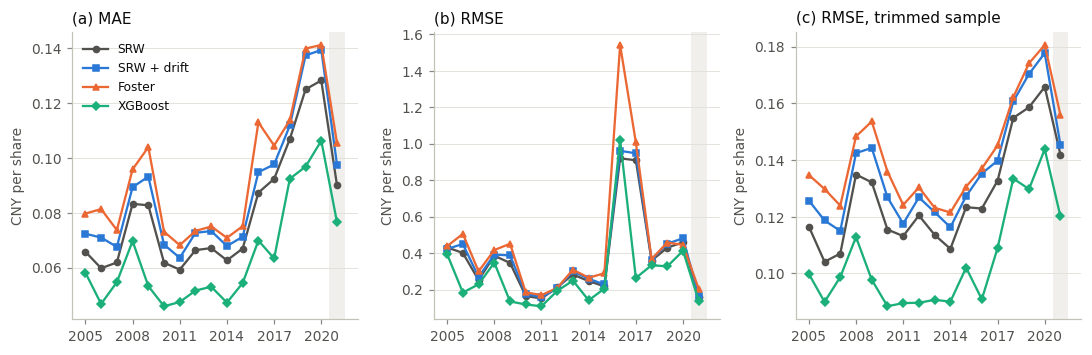

In [23]:
cm_trim = cm.loc[cm_trim.index]          # carry the info_group column into the trimmed sample
annual_trim = annual_table(cm_trim)
by_q_trim = pd.concat({g: accuracy(d, MODELS)[['N', 'MAE', 'RMSE', 'dMAE', 'dRMSE']] for g, d in cm_trim.groupby('info_group')})
YRS = annual.index.astype(int).to_numpy()
YLAB = [str(y) if y < 2021 else '2021\n(Q1)' for y in YRS]


def partial_year(ax):
    ax.axvspan(YRS[-1] - 0.5, YRS[-1] + 0.5, color='#f0efec', lw=0, zorder=0)


fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
for ax, (tab, met, ttl) in zip(axes, [(annual, 'MAE', '(a) MAE'), (annual, 'RMSE', '(b) RMSE'),
                                      (annual_trim, 'RMSE', '(c) RMSE, trimmed sample')]):
    partial_year(ax)
    for m in MODELS:
        ax.plot(YRS, tab[(met, m)].astype(float), color=COL[m], marker=MARK[m], ms=4, lw=1.5, label=LABEL[m])
    ax.set_title(ttl, loc='left')
    ax.set_ylabel('CNY per share')
    ax.set_xticks(YRS[::3], [YLAB[i] for i in range(0, len(YRS), 3)])
axes[0].legend(loc='upper left', ncol=1)
fig.tight_layout()
savefig(fig, 'fig1_annual_accuracy')
plt.show()

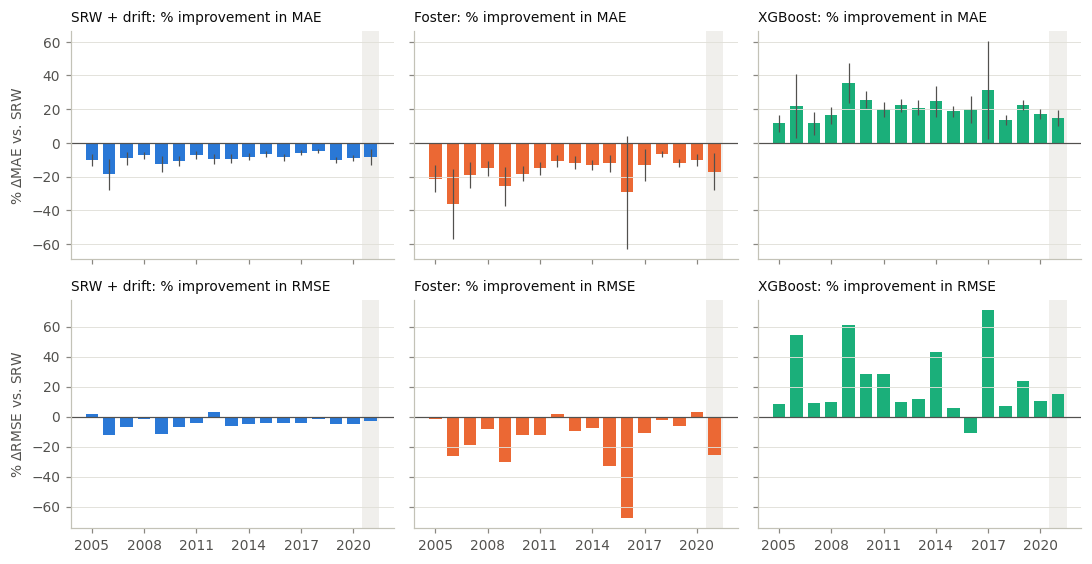

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5.2), sharex=True, sharey='row')
for j, m in enumerate(ALT):
    for i, (met, ttl) in enumerate([('dMAE', 'MAE'), ('dRMSE', 'RMSE')]):
        ax = axes[i, j]
        partial_year(ax)
        v = annual[(met, m)].astype(float)
        kw = {}
        if met == 'dMAE':
            kw = dict(yerr=1.96 * annual[('dMAE_se', m)].astype(float), error_kw=dict(ecolor=INK2, lw=0.8, capsize=0))
        ax.bar(YRS, v, color=COL[m], width=0.72, **kw)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_title(f'{LABEL[m]}: % improvement in {ttl}', loc='left', fontsize=9)
        ax.set_xticks(YRS[::3], [YLAB[k] for k in range(0, len(YRS), 3)])
        if j == 0:
            ax.set_ylabel(f'% $\\Delta${ttl} vs. SRW')
fig.tight_layout()
savefig(fig, 'fig2_annual_improvement')
plt.show()

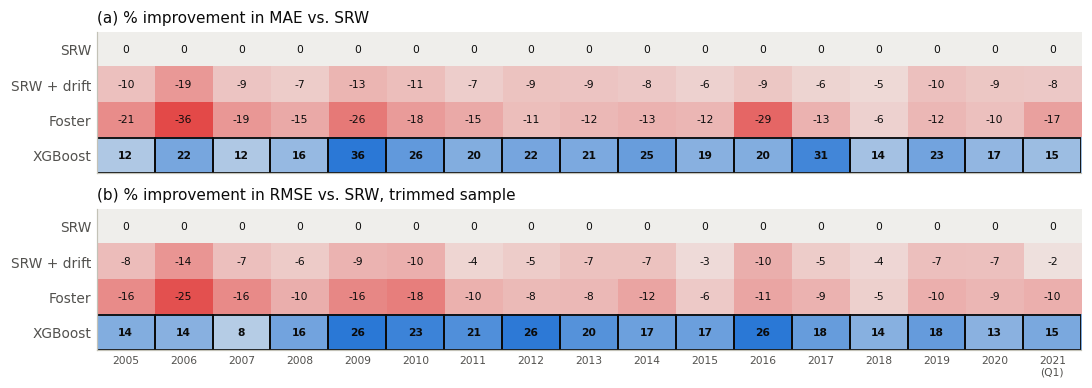

In [25]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
DIV = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])
fig, axes = plt.subplots(2, 1, figsize=(10, 3.6), sharex=True)
for ax, (tab, met, ttl) in zip(axes, [(annual, 'dMAE', '(a) % improvement in MAE vs. SRW'),
                                      (annual_trim, 'dRMSE', '(b) % improvement in RMSE vs. SRW, trimmed sample')]):
    mat = np.vstack([np.zeros(len(YRS))] + [tab[(met, m)].astype(float).to_numpy() for m in ALT])
    lim = np.nanmax(np.abs(mat))
    ax.imshow(mat, cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim), aspect='auto')
    best = mat.argmax(0)
    for (r, c), v in np.ndenumerate(mat):
        ax.text(c, r, f'{v:.0f}', ha='center', va='center', fontsize=7,
                color=INK, fontweight='bold' if best[c] == r else 'normal')
        if best[c] == r:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec=INK, lw=1.2))
    ax.set_yticks(range(4), [LABEL[m] for m in MODELS])
    ax.set_title(ttl, loc='left')
    ax.grid(False)
    ax.tick_params(length=0)
axes[1].set_xticks(range(len(YRS)), YLAB, fontsize=7)
fig.tight_layout()
savefig(fig, 'fig3_best_model_by_year')
plt.show()

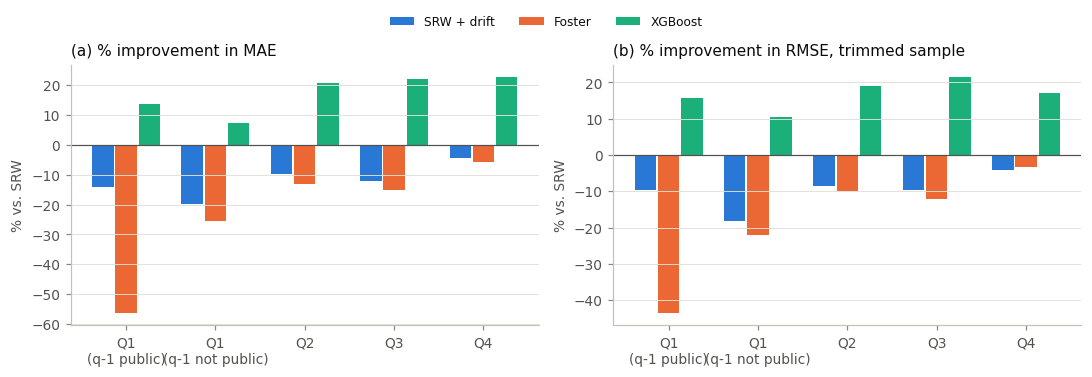

In [26]:
groups = ['Q1, EPS(q-1) known', 'Q1, EPS(q-1) not yet public', 'Q2', 'Q3', 'Q4']
glab = ['Q1\n(q-1 public)', 'Q1\n(q-1 not public)', 'Q2', 'Q3', 'Q4']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=False)
for ax, (tab, met, ttl) in zip(axes, [(by_q, 'dMAE', '(a) % improvement in MAE'),
                                      (by_q_trim, 'dRMSE', '(b) % improvement in RMSE, trimmed sample')]):
    x = np.arange(len(groups))
    for k, m in enumerate(ALT):
        ax.bar(x + (k - 1) * 0.26, [tab.loc[(g, m), met] for g in groups], width=0.24, color=COL[m], label=LABEL[m])
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(x, glab)
    ax.set_title(ttl, loc='left')
    ax.set_ylabel('% vs. SRW')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.07))
fig.tight_layout()
savefig(fig, 'fig4_by_fiscal_quarter')
plt.show()

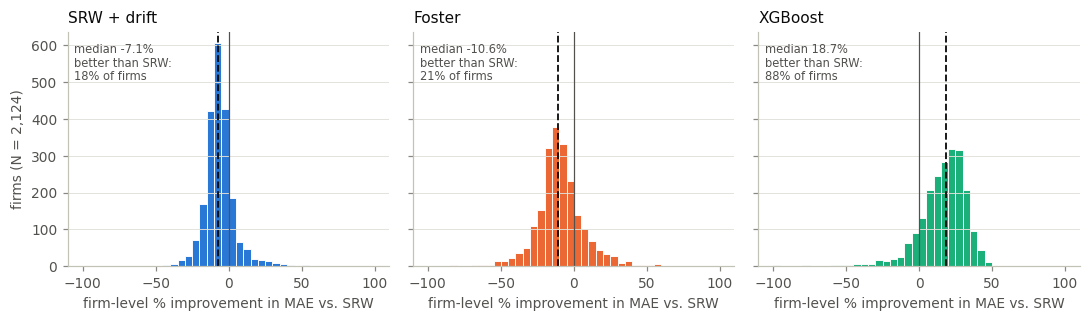

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.0), sharey=True)
bins = np.arange(-100, 105, 5)
for ax, m in zip(axes, ALT):
    v = firm[f'dMAE_{m}'].clip(-100, 100)
    ax.hist(v, bins=bins, color=COL[m], edgecolor='white', linewidth=0.6)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.axvline(v.median(), color=INK, lw=1.2, ls='--')
    ax.set_title(f'{LABEL[m]}', loc='left')
    ax.text(0.02, 0.95, f'median {v.median():.1f}%\nbetter than SRW:\n{100 * (firm[f"MAE_{m}"] < firm.MAE_rw).mean():.0f}% of firms',
            transform=ax.transAxes, ha='left', va='top', fontsize=7.5, color=INK2)
    ax.set_xlabel('firm-level % improvement in MAE vs. SRW')
axes[0].set_ylabel(f'firms (N = {N_FIRMS:,})')
fig.tight_layout()
savefig(fig, 'fig5_firm_improvement_hist')
plt.show()

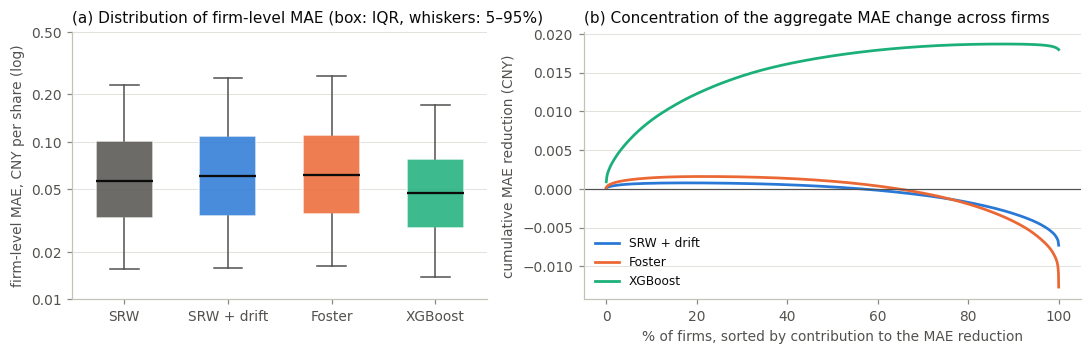

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), gridspec_kw={'width_ratios': [1, 1.2]})
ax = axes[0]
bp = ax.boxplot([firm[f'MAE_{m}'] for m in MODELS], whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True)
for patch, med, m in zip(bp['boxes'], bp['medians'], MODELS):
    patch.set(facecolor=COL[m], alpha=0.85, edgecolor='white')
    med.set(color=INK, linewidth=1.5)
for w in bp['whiskers'] + bp['caps']:
    w.set(color=INK2)
ax.set_yscale('log')
ax.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5], ['0.01', '0.02', '0.05', '0.10', '0.20', '0.50'])
ax.minorticks_off()
ax.set_xticks(range(1, 5), [LABEL[m] for m in MODELS])
ax.set_ylabel('firm-level MAE, CNY per share (log)')
ax.set_title('(a) Distribution of firm-level MAE (box: IQR, whiskers: 5–95%)', loc='left')
ax = axes[1]
for m in ALT:
    c = firm[f'contrib_{m}'].sort_values(ascending=False).to_numpy()
    xs = np.arange(1, len(c) + 1) / len(c) * 100
    ax.plot(xs, np.cumsum(c) / N_FL, color=COL[m], lw=1.8, label=LABEL[m])
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xlabel('% of firms, sorted by contribution to the MAE reduction')
ax.set_ylabel('cumulative MAE reduction (CNY)')
ax.set_title('(b) Concentration of the aggregate MAE change across firms', loc='left')
ax.legend(loc='lower left')
fig.tight_layout()
savefig(fig, 'fig6_firm_distribution_concentration')
plt.show()

## 15. Save the forecast dataset
Saved as Parquet (types preserved), Stata `.dta` (with variable labels) and CSV.

In [29]:
DICT = {
    'permno': 'Firm identifier (Datastream name, from source panel)', 'firm_id': 'Integer firm code (1..N, sorted permno)',
    'exchange': 'Exchange', 'fyear': 'Fiscal year of target quarter', 'fqtr': 'Fiscal quarter (1-4)',
    'fperiod': 'Fiscal period label, e.g. 2008Q1', 'ann_date': 'Announcement date of target EPS (date_qk)',
    'lag_days': 'Days from fiscal quarter end to announcement', 'date_flag': 'Announcement-date quality flag',
    'eps_actual': 'Actual standalone quarterly EPS (CNY, adjusted)', 'eps_lag4': 'EPS same quarter previous year',
    'h_avail': 'Quarters back to latest EPS public before ann_date', 'lag1_avail': 'EPS(q-1) public before ann_date',
    'f_rw': 'M1 forecast: seasonal random walk', 'f_rwd': 'M2 forecast: SRW with drift',
    'f_foster': 'M3 forecast: Foster seasonal AR(1), firm OLS', 'f_xgb': 'M4 forecast: XGBoost (pooled)',
    'f_foster_pooled': 'Robustness: Foster with pooled phi',
    'e_rw': 'Error M1 = actual - forecast (UE)', 'e_rwd': 'Error M2 = actual - forecast (UE)',
    'e_foster': 'Error M3 = actual - forecast (UE)', 'e_xgb': 'Error M4 = actual - forecast (UE)',
    'e_foster_pooled': 'Error Foster pooled phi', 'avail_rw': 'M1 forecast available', 'avail_rwd': 'M2 forecast available',
    'avail_foster': 'M3 forecast available', 'avail_xgb': 'M4 forecast available',
    'avail_foster_pooled': 'Foster pooled-phi forecast available', 'common': 'In common evaluation sample (M1-M4)',
    'est_cutoff': 'Estimation cutoff M (1st day of ann. month)', 'win_start': 'First fiscal quarter of training window',
    'win_end': 'Last fiscal quarter of training window', 'n_eps_window': 'Firm EPS in window public before ann_date',
    'n_ds_drift': 'YoY changes used for drift (M2)', 'n_pairs_foster': 'Foster regression pairs (M3)',
    'drift_mu': 'Estimated drift (M2)', 'foster_alpha': 'Foster intercept (M3)', 'foster_phi': 'Foster phi (M3, capped)',
    'foster_phi_capped': 'Foster OLS phi outside [-1,1]', 'foster_h': 'Foster step: 1 or 2 (EPS q-1 not public)',
    'foster_pooled_phi': 'Pooled phi of the window (robustness)', 'scale_hist': 'Hist. EPS scale (mean |EPS| 8q)',
    'xgb_n_train': 'XGBoost training rows', 'xgb_n_train_firms': 'XGBoost training firms',
    'xgb_train_max_ann': 'Latest announcement in XGBoost training set', 'xgb_tune_year': 'XGBoost tuning year',
    'max_input_date': 'Latest announcement among forecast inputs', 'max_est_date': 'Latest announcement among estimation data'}
out = fc[list(DICT)].copy()
for c in ['h_avail', 'n_eps_window', 'xgb_n_train', 'xgb_n_train_firms', 'xgb_tune_year', 'foster_h']:
    out[c] = out[c].astype('float64')
out.to_parquet(FC_DIR / 'eps_forecasts_oos.parquet', index=False)
out.to_csv(FC_DIR / 'eps_forecasts_oos.csv', index=False)
dta = out.copy()
for c in dta.columns:
    if dta[c].dtype == bool:
        dta[c] = dta[c].astype('int8')
dta.to_stata(FC_DIR / 'eps_forecasts_oos.dta', write_index=False, version=118,
             variable_labels={k: v[:80] for k, v in DICT.items()}, convert_dates={c: 'td' for c in
             ['ann_date', 'est_cutoff', 'xgb_train_max_ann', 'max_input_date', 'max_est_date']})
pd.Series(DICT, name='description').rename_axis('variable').to_csv(FC_DIR / 'eps_forecasts_oos_dictionary.csv')
back = pd.read_parquet(FC_DIR / 'eps_forecasts_oos.parquet')
assert len(back) == len(fc) and back.common.sum() == N_COMMON
assert np.allclose(back.e_xgb, back.eps_actual - back.f_xgb, equal_nan=True)
print(f'saved {len(out):,} rows x {out.shape[1]} columns')

saved 127,454 rows x 48 columns


## 16. LaTeX tables and result macros for the report

In [30]:
def num(x, d=3, signed=False):
    if pd.isna(x):
        return ''
    s = f'{abs(x):,.{d}f}'
    return ('$-$' + s) if x < 0 else (('+' + s) if signed else s)


def write_tex(name, align, header, body):
    lines = [f'\\begin{{tabular}}{{{align}}}', '\\toprule', *header, '\\midrule', *body, '\\bottomrule', '\\end{tabular}']
    (TAB_DIR / f'{name}.tex').write_text('\n'.join(lines) + '\n')


# Table 1: sample and availability
rows = [('Evaluation targets (FY2005Q1--FY2021Q1)', len(fc), 100.0, fc.permno.nunique())]
for m, lab in [('rw', 'M1 SRW: $EPS_{q-4}$ public before $A$'), ('rwd', 'M2 SRW + drift: $\\geq$4 YoY changes'),
               ('foster', 'M3 Foster: $\\geq$8 pairs'), ('xgb', 'M4 XGBoost'),
               ('foster_pooled', 'Foster, pooled $\\phi$: $\\geq$4 pairs')]:
    s_ = fc[fc[f'avail_{m}']]
    rows.append((lab, len(s_), 100 * len(s_) / len(fc), s_.permno.nunique()))
rows.append(('Common sample (M1--M4 all available)', N_COMMON, 100 * N_COMMON / len(fc), N_FIRMS_COMMON))
rows.append((f'Firms with $\\geq${MIN_FIRM_OBS} common-sample forecasts', N_FL, 100 * N_FL / len(fc), N_FIRMS))
write_tex('tab1_sample', 'lrrr', ['& Firm-quarters & \\% of targets & Firms \\\\'],
          [f'{a} & {b:,} & {num(c, 1)} & {d:,} \\\\' for a, b, c, d in rows])

# Table 2: overall accuracy
def overall_rows(tab, tst):
    out = []
    for m in MODELS:
        r = tab.loc[m]
        sm_ = '' if m == 'rw' else stars(tst.loc[(m, 'abs'), 'p_2way'])
        sr_ = '' if m == 'rw' else stars(tst.loc[(m, 'sq'), 'p_2way'])
        out.append(f'{LABEL[m]} & {num(r.MAE, 4)} & {num(r.RMSE, 4)} & '
                   f'{"--" if m == "rw" else num(r.dMAE, 1) + sm_} & {"--" if m == "rw" else num(r.dRMSE, 1) + sr_} & '
                   f'{num(r.MedAE, 4)} & {"--" if m == "rw" else num(r.dsMAE, 1)} \\\\')
    return out


own_rows = []
for m in MODELS:
    s_ = fc[fc[f'avail_{m}']]
    a = accuracy(s_, [m]).loc[m]
    own_rows.append(f'{LABEL[m]} & {num(a.MAE, 4)} & {num(a.RMSE, 4)} & {"--" if m == "rw" else num(a.dMAE, 1)} & '
                    f'{"--" if m == "rw" else num(a.dRMSE, 1)} & {num(a.MedAE, 4)} & {len(s_):,} \\\\')
hdr = ['& MAE & RMSE & \\%$\\Delta$MAE & \\%$\\Delta$RMSE & MedAE & \\%$\\Delta$sMAE \\\\']
body = ([f'\\multicolumn{{7}}{{l}}{{\\emph{{Panel A: common sample (N = {N_COMMON:,})}}}} \\\\'] + overall_rows(overall, tests)
        + ['\\midrule', f'\\multicolumn{{7}}{{l}}{{\\emph{{Panel B: trimmed common sample (N = {len(cm_trim):,})}}}} \\\\']
        + overall_rows(overall_trim, tests_trim)
        + ['\\midrule', '\\multicolumn{7}{l}{\\emph{Panel C: model-specific samples (each vs.\\ SRW on the same forecasts; last column = N)}} \\\\']
        + own_rows
        + ['\\midrule', '\\multicolumn{7}{l}{\\emph{Panel D: robustness, Foster with pooled $\\phi$ (common sample)}} \\\\',
           f'{LABEL["foster_pooled"]} & {num(robust.MAE.iat[0], 4)} & {num(robust.RMSE.iat[0], 4)} & {num(robust.dMAE.iat[0], 1)} & '
           f'{num(robust.dRMSE.iat[0], 1)} & {num(robust.MedAE.iat[0], 4)} & {num(robust.dsMAE.iat[0], 1)} \\\\'])
write_tex('tab2_overall', 'lrrrrrr', hdr, body)

# Table 3: paired tests
body = []
for nm, tt in [('Common sample', tests), ('Trimmed sample', tests_trim)]:
    body.append(f'\\multicolumn{{7}}{{l}}{{\\emph{{{nm}}}}} \\\\')
    for m in ALT:
        for loss, ll in (('abs', 'absolute'), ('sq', 'squared')):
            r = tt.loc[(m, loss)]
            body.append(f'{LABEL[m] if loss == "abs" else ""} & {ll} & {num(r.mean_d, 4)} & {num(r.t_2way, 2)} & '
                        f'{num(r.t_dm, 2)} & {num(r.p_dm, 3)} & {num(r.share_quarters_better, 1)} \\\\')
    if nm == 'Common sample':
        body.append('\\midrule')
write_tex('tab3_tests', 'llrrrrr',
          ['Model & Loss & $\\bar d$ & $t_{\\text{firm, quarter}}$ & $t_{\\text{DM}}$ & $p_{\\text{DM}}$ & \\% quarters $d>0$ \\\\'], body)

# Table 4: annual
body = []
for y in YRS:
    r = annual.loc[y]
    cells = [str(y) if y < 2021 else '2021 (Q1)', f'{int(r["N"].iloc[0]):,}', num(r[('MAE', 'rw')], 4)]
    cells += [num(r[('dMAE', m)], 1) + stars(r[('p_MAE', m)]) for m in ALT]
    cells += [num(r[('RMSE', 'rw')], 4)] + [num(r[('dRMSE', m)], 1) for m in ALT]
    cells += [num(annual_trim.loc[y, ('dRMSE', 'xgb')], 1)]
    cells += [LABEL[r[('best', 'MAE')]], LABEL[r[('best', 'RMSE')]]]
    body.append(' & '.join(cells) + ' \\\\')
write_tex('tab4_annual', 'lrr rrr r rrr r ll',
          ['& & \\multicolumn{4}{c}{MAE} & \\multicolumn{5}{c}{RMSE} & \\multicolumn{2}{c}{Best model} \\\\',
           '\\cmidrule(lr){3-6}\\cmidrule(lr){7-11}\\cmidrule(lr){12-13}',
           'FY & N & SRW & Drift & Foster & XGB & SRW & Drift & Foster & XGB & XGB$^{\\text{trim}}$ & MAE & RMSE \\\\'], body)

# Table 5: firm level
body = []
for m in MODELS:
    r = firm_dist.loc[m]
    cells = [LABEL[m], num(r['firm MAE p10'], 4), num(r['firm MAE p50'], 4), num(r['firm MAE p90'], 4)]
    if m == 'rw':
        cells += ['--'] * 6
    else:
        cf = conc_f.loc[m]
        cells += [num(r['dMAE median'], 1), f'[{num(r["dMAE p25"], 1)}, {num(r["dMAE p75"], 1)}]',
                  num(r['% firms better (MAE)'], 1), num(r['% firms better (RMSE)'], 1),
                  num(cf['dMAE excl. top 5% contributors'], 1),
                  num(cf['dMAE excl. 5% hardest firms (highest SRW MAE)'], 1)]
    body.append(' & '.join(cells) + ' \\\\')
write_tex('tab5_firm', 'lrrr rr rr rr',
          ['& \\multicolumn{3}{c}{Firm-level MAE} & \\multicolumn{2}{c}{Firm \\%$\\Delta$MAE} & \\multicolumn{2}{c}{\\% firms beating SRW} & \\multicolumn{2}{c}{Pooled \\%$\\Delta$MAE excl.} \\\\',
           '\\cmidrule(lr){2-4}\\cmidrule(lr){5-6}\\cmidrule(lr){7-8}\\cmidrule(lr){9-10}',
           'Model & p10 & p50 & p90 & median & IQR & MAE & RMSE & top-5\\% contrib. & 5\\% hardest \\\\'], body)

# Table 6: by fiscal quarter / information set
body = []
for g_, gl in zip(groups, ['Q1, $EPS_{q-1}$ public', 'Q1, $EPS_{q-1}$ not yet public', 'Q2', 'Q3', 'Q4']):
    cells = [gl, f'{int(by_q.loc[(g_, "rw"), "N"]):,}', num(by_q.loc[(g_, 'rw'), 'MAE'], 4)]
    cells += [num(by_q.loc[(g_, m), 'dMAE'], 1) for m in ALT] + [num(by_q_trim.loc[(g_, m), 'dRMSE'], 1) for m in ALT]
    body.append(' & '.join(cells) + ' \\\\')
write_tex('tab6_quarter', 'lrr rrr rrr',
          ['& & & \\multicolumn{3}{c}{\\%$\\Delta$MAE} & \\multicolumn{3}{c}{\\%$\\Delta$RMSE (trimmed)} \\\\',
           '\\cmidrule(lr){4-6}\\cmidrule(lr){7-9}',
           'Target & N & MAE$_{\\text{SRW}}$ & Drift & Foster & XGB & Drift & Foster & XGB \\\\'], body)

# result macros
yr_best_mae = int((annual[('best', 'MAE')] == 'xgb').sum())
yr_best_rmse = int((annual[('best', 'RMSE')] == 'xgb').sum())
mac = {
    'NTargets': f'{len(fc):,}', 'NCommon': f'{N_COMMON:,}', 'NFirmsCommon': f'{N_FIRMS_COMMON:,}',
    'PctCommon': num(100 * N_COMMON / len(fc), 1), 'NTrim': f'{len(cm_trim):,}', 'NFirmsFL': f'{N_FIRMS:,}',
    'NYears': str(len(YRS)), 'NQuarters': str(int(tests.loc[('xgb', 'abs'), 'n_quarters'])),
    'MAErw': num(overall.loc['rw', 'MAE'], 4), 'RMSErw': num(overall.loc['rw', 'RMSE'], 4),
    'MAExgb': num(overall.loc['xgb', 'MAE'], 4), 'RMSExgb': num(overall.loc['xgb', 'RMSE'], 4),
    'dMAExgb': num(overall.loc['xgb', 'dMAE'], 1), 'dRMSExgb': num(overall.loc['xgb', 'dRMSE'], 1),
    'dMAErwd': num(overall.loc['rwd', 'dMAE'], 1), 'dRMSErwd': num(overall.loc['rwd', 'dRMSE'], 1),
    'dMAEfoster': num(overall.loc['foster', 'dMAE'], 1), 'dRMSEfoster': num(overall.loc['foster', 'dRMSE'], 1),
    'dMAEpooled': num(robust.dMAE.iat[0], 1), 'dRMSEpooled': num(robust.dRMSE.iat[0], 1),
    'dMAExgbTrim': num(overall_trim.loc['xgb', 'dMAE'], 1), 'dRMSExgbTrim': num(overall_trim.loc['xgb', 'dRMSE'], 1),
    'dMAEfosterTrim': num(overall_trim.loc['foster', 'dMAE'], 1), 'dRMSEfosterTrim': num(overall_trim.loc['foster', 'dRMSE'], 1),
    'dMAErwdTrim': num(overall_trim.loc['rwd', 'dMAE'], 1), 'dRMSErwdTrim': num(overall_trim.loc['rwd', 'dRMSE'], 1),
    'dsMAExgb': num(overall.loc['xgb', 'dsMAE'], 1), 'MedAErw': num(overall.loc['rw', 'MedAE'], 4),
    'MedAExgb': num(overall.loc['xgb', 'MedAE'], 4),
    'tMAExgb': num(tests.loc[('xgb', 'abs'), 't_2way'], 2), 'tRMSExgb': num(tests.loc[('xgb', 'sq'), 't_2way'], 2),
    'tDMMAExgb': num(tests.loc[('xgb', 'abs'), 't_dm'], 2), 'tDMRMSExgb': num(tests.loc[('xgb', 'sq'), 't_dm'], 2),
    'tRMSExgbTrim': num(tests_trim.loc[('xgb', 'sq'), 't_2way'], 2), 'tDMRMSExgbTrim': num(tests_trim.loc[('xgb', 'sq'), 't_dm'], 2),
    'QbetterMAExgb': num(tests.loc[('xgb', 'abs'), 'share_quarters_better'], 1),
    'QbetterRMSExgbTrim': num(tests_trim.loc[('xgb', 'sq'), 'share_quarters_better'], 1),
    'YearsBestMAExgb': str(yr_best_mae), 'YearsBestRMSExgb': str(yr_best_rmse),
    'MinAnnualdMAExgb': num(annual[('dMAE', 'xgb')].astype(float).min(), 1),
    'MaxAnnualdMAExgb': num(annual[('dMAE', 'xgb')].astype(float).max(), 1),
    'FirmBetterxgb': num(firm_dist.loc['xgb', '% firms better (MAE)'], 1),
    'FirmBetterRMSExgb': num(firm_dist.loc['xgb', '% firms better (RMSE)'], 1),
    'FirmBetterrwd': num(firm_dist.loc['rwd', '% firms better (MAE)'], 1),
    'FirmBetterfoster': num(firm_dist.loc['foster', '% firms better (MAE)'], 1),
    'FirmMedxgb': num(firm_dist.loc['xgb', 'dMAE median'], 1),
    'TopTenSharexgb': num(conc_f.loc['xgb', 'share of gain from top 10%'], 1),
    'ExclTopFivexgb': num(conc_f.loc['xgb', 'dMAE excl. top 5% contributors'], 1),
    'ExclTopTenxgb': num(conc_f.loc['xgb', 'dMAE excl. top 10% contributors'], 1),
    'ExclHardxgb': num(conc_f.loc['xgb', 'dMAE excl. 5% hardest firms (highest SRW MAE)'], 1),
    'PhiFirmMed': num(cm.foster_phi.median(), 2), 'PhiPooledMed': num(cm.foster_pooled_phi.median(), 2),
    'PhiCapped': num(100 * cm.foster_phi_capped.mean(), 1),
    'dMAExgbQoneNP': num(by_q.loc[('Q1, EPS(q-1) not yet public', 'xgb'), 'dMAE'], 1),
    'dMAExgbQoneP': num(by_q.loc[('Q1, EPS(q-1) known', 'xgb'), 'dMAE'], 1),
    'dMAEfosterQoneP': num(by_q.loc[('Q1, EPS(q-1) known', 'foster'), 'dMAE'], 1),
    'SameDayLate': num(100 * order_q14.loc[2019:2021, 'same day'].mean(), 0),
    'SameDayEarly': num(100 * order_q14.loc[2005:2012, 'same day'].mean(), 0),
    'XcheckN': f'{int(xcheck.iloc[1]):,}', 'XcheckPct': num(xcheck.iloc[2], 1),
    'LookaheadN': f'{int(sub.sum()):,}', 'TopImp': importance.index[0].replace('_', '\\_'),
    'TopImpShare': num(100 * importance.iloc[0], 1),
    'GainTopOnePctObs': num(conc_obs.loc[('xgb', 'top 1%'), 'share_of_total_gain'], 1),
    'GainTopTenPctObs': num(conc_obs.loc[('xgb', 'top 1%'), 'share_of_total_gain']
                            + conc_obs.loc[('xgb', '90-99%'), 'share_of_total_gain'], 1),
    'XGBfits': str(int(BATCH_LOG.importance.notna().sum())), 'XGBbatches': str(len(BATCH_LOG)),
    'PeriodOne': num(by_period.loc[('2005-2009', 'xgb'), 'dMAE'], 1),
    'PeriodTwo': num(by_period.loc[('2010-2014', 'xgb'), 'dMAE'], 1),
    'PeriodThree': num(by_period.loc[('2015-2021Q1', 'xgb'), 'dMAE'], 1),
}
(REPORT_DIR / 'results_macros.tex').write_text('\n'.join(f'\\newcommand{{\\{k}}}{{{v}}}' for k, v in mac.items()) + '\n')
display(pd.Series(mac).to_frame('value'))

,value
NTargets,"127,454"
NCommon,"95,732"
NFirmsCommon,"2,751"
PctCommon,75.1
NTrim,"94,774"
...,...
XGBfits,129
XGBbatches,232
PeriodOne,21.0
PeriodTwo,22.7


## 17. Verification of saved outputs and runtime

In [31]:
expected = ([FC_DIR / f'eps_forecasts_oos.{e}' for e in ('parquet', 'csv', 'dta')]
            + [FC_DIR / 'eps_forecasts_oos_dictionary.csv', REPORT_DIR / 'results_macros.tex']
            + [TAB_DIR / f'{n}.tex' for n in ('tab1_sample', 'tab2_overall', 'tab3_tests', 'tab4_annual', 'tab5_firm', 'tab6_quarter')]
            + [TAB_DIR / f'{n}.csv' for n in ('overall_common', 'overall_trimmed', 'annual_accuracy', 'firm_level_metrics',
                                              'firm_level_distribution', 'paired_tests_common', 'availability_by_year')]
            + [FIG_DIR / f'{n}.{e}' for n in ('fig0_reporting_timing', 'fig1_annual_accuracy', 'fig2_annual_improvement',
                                              'fig3_best_model_by_year', 'fig4_by_fiscal_quarter',
                                              'fig5_firm_improvement_hist', 'fig6_firm_distribution_concentration')
               for e in ('pdf', 'png')])
status = pd.DataFrame({'file': [str(p.relative_to(ROOT)) for p in expected],
                       'exists': [p.exists() for p in expected],
                       'kB': [round(p.stat().st_size / 1024, 1) if p.exists() else 0 for p in expected]})
display(status)
assert status.exists.all() and (status.kB > 0).all(), 'missing output'
chk = pd.read_stata(FC_DIR / 'eps_forecasts_oos.dta')
assert len(chk) == len(fc) and int(chk.common.sum()) == N_COMMON
print(f'all {len(expected)} outputs verified; total runtime {(time.time() - T_START) / 60:.1f} min '
      f'(main forecasting run {RUNTIME_MAIN / 60:.1f} min)')

,file,exists,kB
0,output/forecasts/eps_forecasts_oos.parquet,True,11763.6
1,output/forecasts/eps_forecasts_oos.csv,True,59704.7
2,output/forecasts/eps_forecasts_oos.dta,True,44465.2
3,output/forecasts/eps_forecasts_oos_dictionary.csv,True,2.1
4,report/results_macros.tex,True,2.2
5,output/tables/tab1_sample.tex,True,0.6
6,output/tables/tab2_overall.tex,True,1.3
7,output/tables/tab3_tests.tex,True,1.0
8,output/tables/tab4_annual.tex,True,2.3
9,output/tables/tab5_firm.tex,True,0.7


all 32 outputs verified; total runtime 3.0 min (main forecasting run 2.3 min)


## 18. Methodological compromises and limitations

* **Publication dates before FY2004 are vendor backfill dates** (mostly Nov 2003 – Jan 2004). They are used
  as availability dates. This is conservative (no leakage) but shrinks the effective training data for the
  first forecasts in 2005, because FY2003 records cannot use FY2002 lags that appear to arrive late. Q1/Q3
  coverage before FY2002 is sparse. Together these make 12 quarters the longest window feasible from 2005.
* **EPS is retroactively adjusted for capital changes** and may include later restatements stored by the
  vendor. Forecast inputs are therefore not exactly the as-first-reported figures. This affects all models
  equally and matches the EPS used in the existing SUE construction (the M1 cross-check matches 100%).
* **Common estimation cutoff.** Parameters use data announced before the first day of the announcement
  month, while forecast inputs use everything announced before the announcement day. This lets the pooled
  XGBoost be refit monthly instead of daily, and is applied to all models.
* **Same-day Q4/Q1 releases** leave $EPS_{q-1}$ unobserved at the forecast origin for a growing share of Q1
  targets. Foster switches to its two-step form, XGBoost sees the missing lag explicitly, and results are
  reported separately for this group.
* **Extreme EPS values** (e.g. ANTONG HOLDINGS 2016, |EPS| > 27 CNY per quarter) are kept, because dropping
  data by value would be ad hoc. They dominate full-sample RMSE, so results are also reported on a
  symmetrically trimmed sample and with median and scaled errors.
* **Firm-specific Foster** with at most 12 pairs is noisy (φ estimates near 0.1, a few capped at ±1). The
  pooled-φ variant reduces but does not remove the gap to the SRW. Neither variant is preferred to the SRW.
* **XGBoost** uses a deliberately small grid, re-tuned annually; its depth cap (4) is often binding, so a
  larger grid could change its accuracy. Feature importance is descriptive only.
* **Firm identifiers** are Datastream names (`permno`). `firm_id` is a convenience integer code.